# Predictive Waste Classification — XGBoost (Improved)
## Thread Dyeing Factory | Circular Supply Chain

**Improvements applied over baseline (mirrors the Random Forest notebook):**

| # | Technique | Detail |
|---|-----------|--------|
| 1 | Lag & Rolling Features | lag-1, lag-7, roll-7, roll-30, std-7 for all 4 targets + production |
| 2 | Interaction Features | Prod×DyeBatch, Prod×Acid, Fixation_loss_kg, etc. |
| 3 | Skew Check | All 4 targets verified within ±0.5 → **no log transform needed** |
| 4 | Walk-Forward CV | `TimeSeriesSplit(n_splits=5, gap=7)` replaces random KFold |
| 5 | XGBoost extras | Gradient boosting, native gain importance, SHAP, learning curves |

**Workflow:** Train on 2023 → Test on 2024 | Targets: Solid_Waste_kg, Yarn_Waste_kg, Chemical_Waste_kg, Wastewater_L

In [2]:
# ============================================================
# CELL 0: Install Required Packages
# ============================================================
# Run this cell FIRST — installs all dependencies.
# This is required once per environment.
# Restart the kernel after installation if prompted.

import subprocess, sys

packages = [
    'xgboost',
    'shap',
    'pandas',
    'numpy',
    'scikit-learn',
    'matplotlib',
    'seaborn',
    'openpyxl',
    'joblib',
]

for pkg in packages:
    result = subprocess.run(
        [sys.executable, '-m', 'pip', 'install', pkg, '--quiet'],
        capture_output=True, text=True
    )
    status = 'Installed' if result.returncode == 0 else 'No Failed'
    print(f'{status}  {pkg}')

print('\n All packages installed. You may need to restart the kernel once.')

Installed  xgboost
Installed  shap
Installed  pandas
Installed  numpy
Installed  scikit-learn
Installed  matplotlib
Installed  seaborn
Installed  openpyxl
Installed  joblib

 All packages installed. You may need to restart the kernel once.


In [3]:
# ============================================================
# CELL 1: Project Header & Description
# ============================================================
# Title: Predictive Waste Classification and Reverse Logistics Optimization
#        Using Machine Learning in Circular Supply Chain
#        (Thread Dyeing Factory)
# Model: XGBoost Regressor (Multi-Output, Per-Target Tuned)

# WORKFLOW:
#   - Train on Year 1 (2023) data
#   - Test on Year 2 (2024) data
#   - Predict 4 waste outputs simultaneously:
#       Solid_Waste_kg, Yarn_Waste_kg, Chemical_Waste_kg, Wastewater_L
#
# KEY DIFFERENCES vs RANDOM FOREST:
#   - XGBRegressor replaces RandomForestRegressor
#   - Gradient boosting (sequential) vs bagging (parallel)
#   - Additional hyperparams: learning_rate, subsample, colsample_bytree
#   - Native XGBoost gain-based feature importance
#   - Early stopping learning curves on a validation split
#   - SHAP values for model explainability

In [4]:
# Importing Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.inspection import permutation_importance
import joblib

# SHAP is optional — cell will be skipped gracefully if unavailable
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print('⚠  SHAP not installed — SHAP cell will be skipped. Run: pip install shap')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
COLORS = ['#2196F3', '#4CAF50', '#FF5722', '#9C27B0']   # one per waste target

OUTPUT_DIR = "output_figures_xgb"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGETS = ['Solid_Waste_kg', 'Yarn_Waste_kg', 'Chemical_Waste_kg', 'Wastewater_L']

# Skew analysis on the dataset — ALL targets are within ±0.5,
# so NO Log transform is applied (transforming near-normal data hurts performance).
#   Chemical_Waste_kg : skew = 0.31  → within ±0.5 → no transform
#   Solid_Waste_kg    : skew = 0.38  → within ±0.5 → no transform
#   Yarn_Waste_kg     : skew = 0.39  → within ±0.5 → no transform
#   Wastewater_L      : skew = 0.35  → within ±0.5 → no transform
LOG_TARGETS = set()   # empty → no target is Log-transformed

print(f" All figures will be saved to: '{OUTPUT_DIR}/'")

 All figures will be saved to: 'output_figures_xgb/'


In [5]:
# Load Dataset
FILE_PATH = "Textile_Dyeing_Dataset_Causal.xlsx"
SHEET     = "Sheet1"

df_raw = pd.read_excel(FILE_PATH, sheet_name=SHEET)
df_raw['Date'] = pd.to_datetime(df_raw['Date'])

# Rename column with special character (causes issues in some sklearn/xgboost ops)
df_raw = df_raw.rename(columns={'Liquor_Ratio_1:x': 'Liquor_Ratio_1x'})

print(f" Dataset loaded and Dates converted | Shape: {df_raw.shape}")

 Dataset loaded and Dates converted | Shape: (731, 39)


In [6]:
# Data Exploration
print("=" * 60)
print("BASIC DATASET INFO")
print("=" * 60)
df_raw.info()

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS (numeric columns)")
print("=" * 60)
display(df_raw.describe().T)

print("\n" + "=" * 60)
print("TARGET VARIABLE SKEWNESS — justifies no-log-transform decision")
print("=" * 60)
for t in TARGETS:
    skew = df_raw[t].skew()
    flag = "→ LOG TRANSFORM applied" if t in LOG_TARGETS else "→ no transform needed (within ±0.5)"
    print(f"  {t:<25}: skew = {skew:.4f}  {flag}")

BASIC DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 39 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   Date                           731 non-null    datetime64[us]
 1   Month                          731 non-null    str           
 2   Year                           731 non-null    int64         
 3   Day_Type                       731 non-null    str           
 4   Monthly_Demand_Factor          731 non-null    float64       
 5   Production_Volume_ton          731 non-null    float64       
 6   Production_Volume_kg           731 non-null    int64         
 7   Machine_Utilization_%          731 non-null    float64       
 8   Number_of_Workers              731 non-null    int64         
 9   Energy_Consumption_kWh_per_kg  731 non-null    float64       
 10  Total_Energy_kWh               731 non-null    float64       
 11  Water_Consu

,count,mean,min,25%,50%,75%,max,std
Date,731,2024-01-01 00:00:00,2023-01-01 00:00:00,2023-07-02 12:00:00,2024-01-01 00:00:00,2024-07-01 12:00:00,2024-12-31 00:00:00,NaN
Year,731.0,2023.500684,2023.0,2023.0,2024.0,2024.0,2024.0,0.500342
Monthly_Demand_Factor,731.0,1.071477,0.8,0.9,1.05,1.25,1.35,0.170184
Production_Volume_ton,731.0,13.903502,7.01,11.89,13.8,15.93,21.28,2.733132
Production_Volume_kg,731.0,13902.924761,7008.0,11888.5,13802.0,15930.5,21279.0,2733.027916
Machine_Utilization_%,731.0,83.284542,75.0,80.9,83.2,85.7,91.0,3.376083
Number_of_Workers,731.0,94.841313,52.0,82.0,94.0,107.0,141.0,17.752468
Energy_Consumption_kWh_per_kg,731.0,1.71172,1.6,1.631,1.698,1.7745,2.04,0.092452
Total_Energy_kWh,731.0,23851.568263,11493.8,20157.5,23486.0,27530.1,39127.9,5104.44952
Water_Consumption_L_per_kg,731.0,51.623735,36.94,47.7,51.71,55.31,65.0,5.387519



TARGET VARIABLE SKEWNESS — justifies no-log-transform decision
  Solid_Waste_kg           : skew = 0.3805  → no transform needed (within ±0.5)
  Yarn_Waste_kg            : skew = 0.3918  → no transform needed (within ±0.5)
  Chemical_Waste_kg        : skew = 0.3096  → no transform needed (within ±0.5)
  Wastewater_L             : skew = 0.3505  → no transform needed (within ±0.5)


In [7]:
# Data Exploration - Missing Values
missing      = df_raw.isnull().sum()
missing_pct  = (missing / len(df_raw)) * 100
missing_df   = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df   = missing_df[missing_df['Missing Count'] > 0]

if missing_df.empty:
    print(" No missing values found in the dataset!")
else:
    print("⚠  Missing values detected:")
    print(missing_df)
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(df_raw.isnull(), yticklabels=False, cbar=True, cmap='viridis', ax=ax)
    ax.set_title("Missing Value Heatmap", fontsize=14, fontweight='bold')
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/01_missing_value_heatmap.png", dpi=150)
    plt.show()
    print(" Saved: 01_missing_value_heatmap.png")

 No missing values found in the dataset!


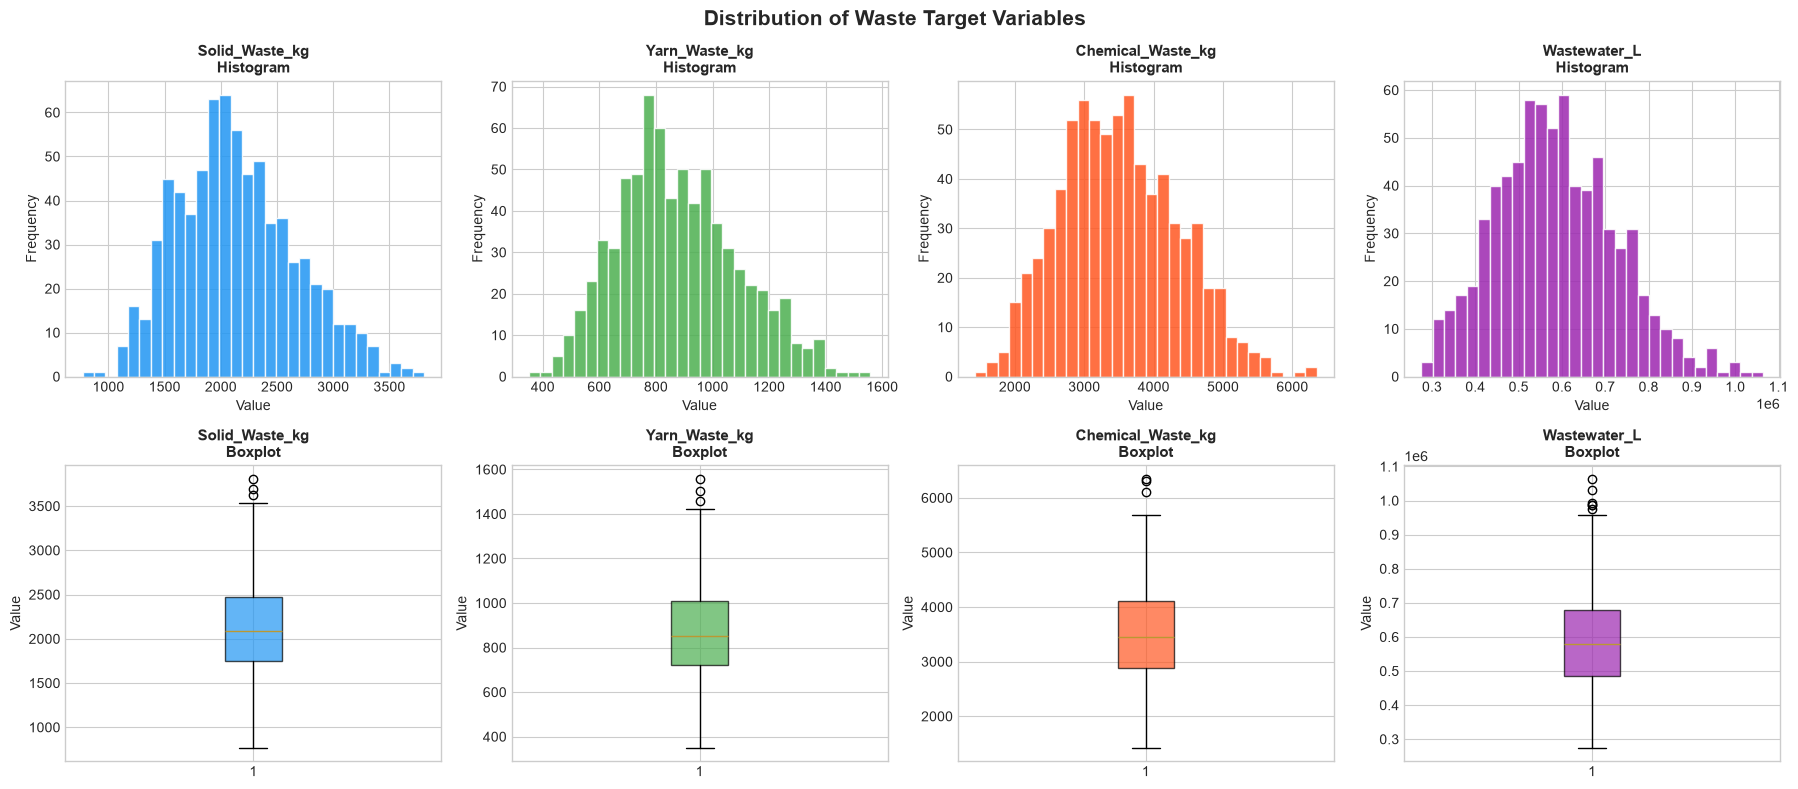

 Saved: 02_target_distributions.png


In [8]:
# Data Exploration — Distribution of Target Variables
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    axes[0, i].hist(df_raw[target].dropna(), bins=30, color=color, edgecolor='white', alpha=0.85)
    axes[0, i].set_title(f'{target}\nHistogram', fontsize=11, fontweight='bold')
    axes[0, i].set_xlabel('Value')
    axes[0, i].set_ylabel('Frequency')

    axes[1, i].boxplot(df_raw[target].dropna(), patch_artist=True,
                       boxprops=dict(facecolor=color, alpha=0.7))
    axes[1, i].set_title(f'{target}\nBoxplot', fontsize=11, fontweight='bold')
    axes[1, i].set_ylabel('Value')

plt.suptitle("Distribution of Waste Target Variables", fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/02_target_distributions.png", dpi=150, bbox_inches='tight')
plt.show()
print(" Saved: 02_target_distributions.png")

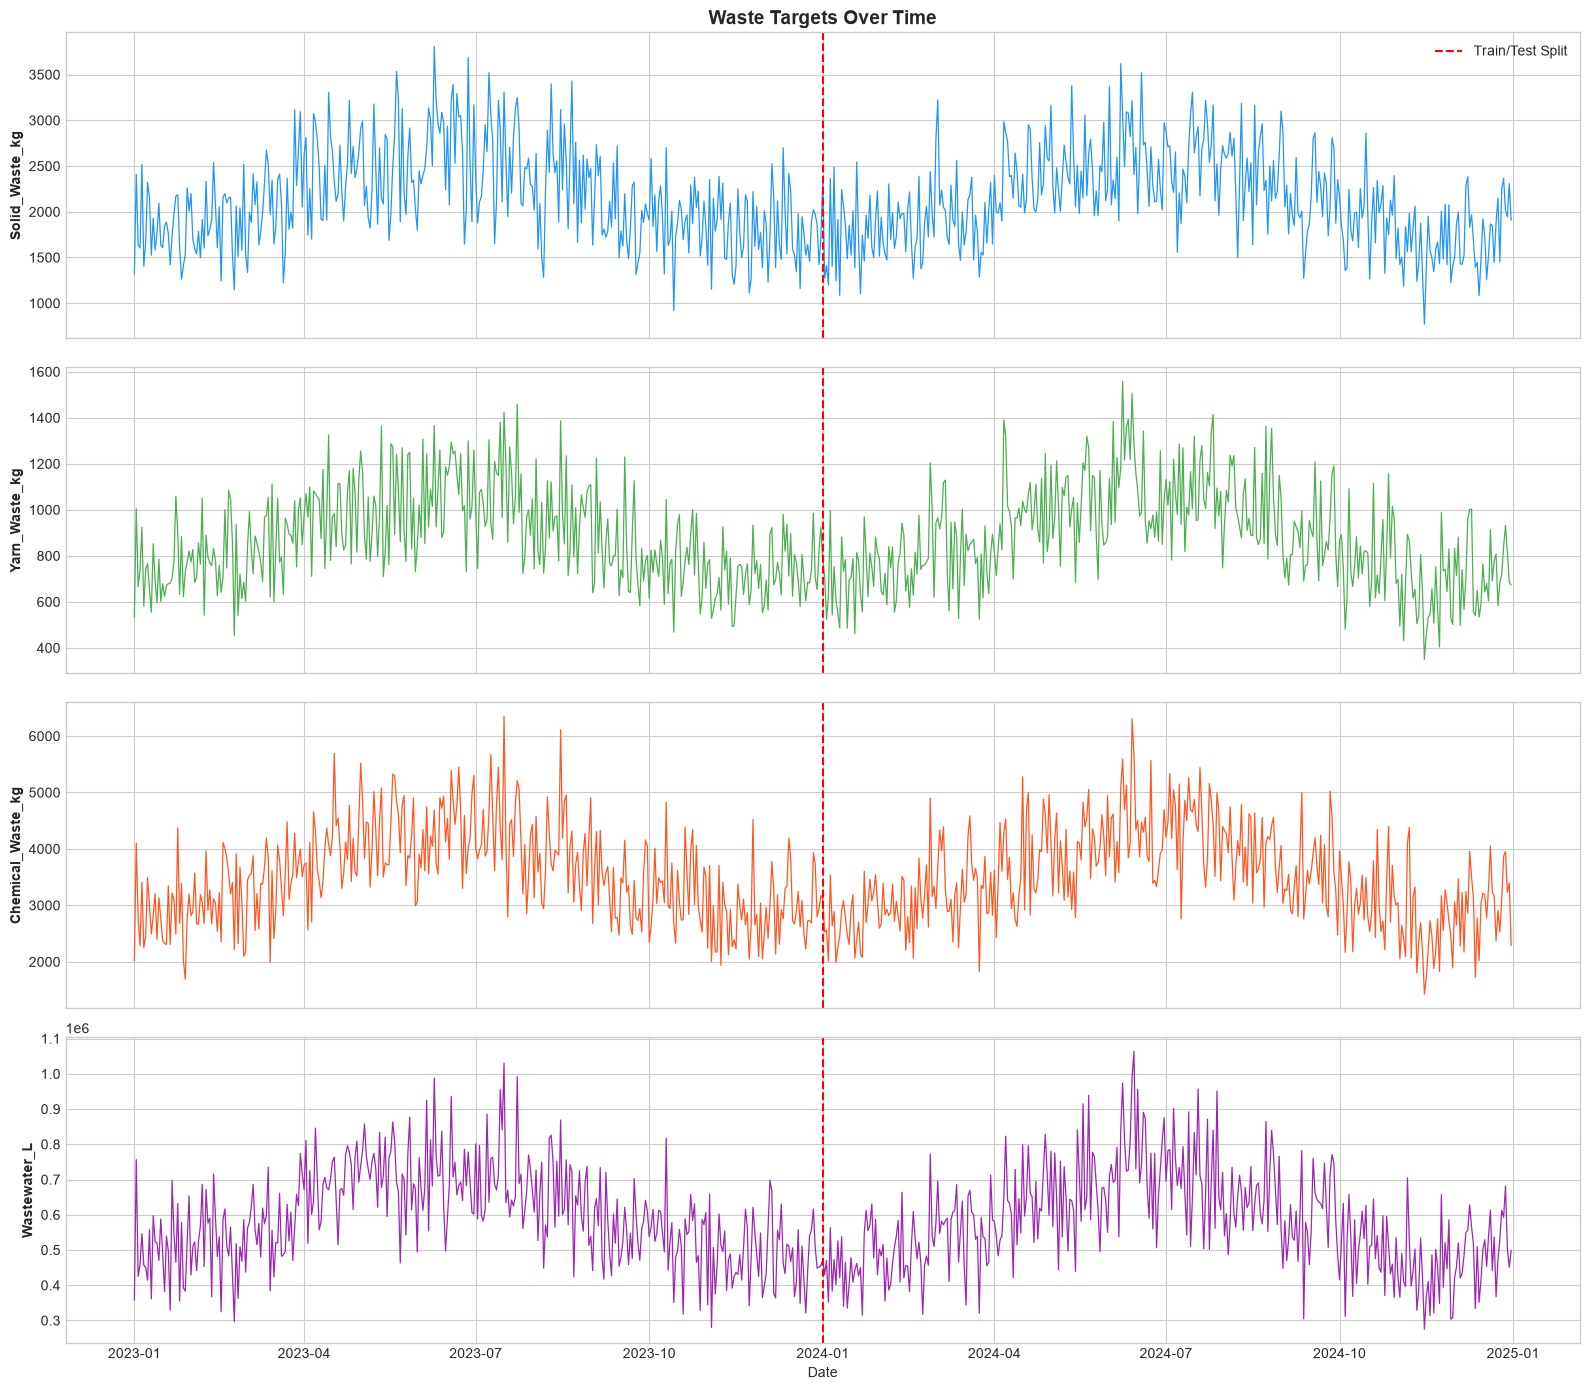

Saved: 03_targets_over_time.png


In [9]:
# Data Exploration — Target Variables Over Time
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()

df_sorted  = df_raw.sort_values('Date').copy()
split_date = pd.Timestamp('2024-01-01')

fig, axes = plt.subplots(4, 1, figsize=(16, 14), sharex=True)
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    axes[i].plot(df_sorted['Date'], df_sorted[target], color=color, linewidth=0.9)
    axes[i].axvline(split_date, color='red', linestyle='--', linewidth=1.5, label='Train/Test Split')
    axes[i].set_ylabel(target, fontsize=10, fontweight='bold')
    if i == 0:
        axes[i].legend(fontsize=10)

axes[0].set_title("Waste Targets Over Time", fontsize=14, fontweight='bold')
plt.xlabel("Date")
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/03_targets_over_time.png", dpi=150)
plt.show()
print("Saved: 03_targets_over_time.png")

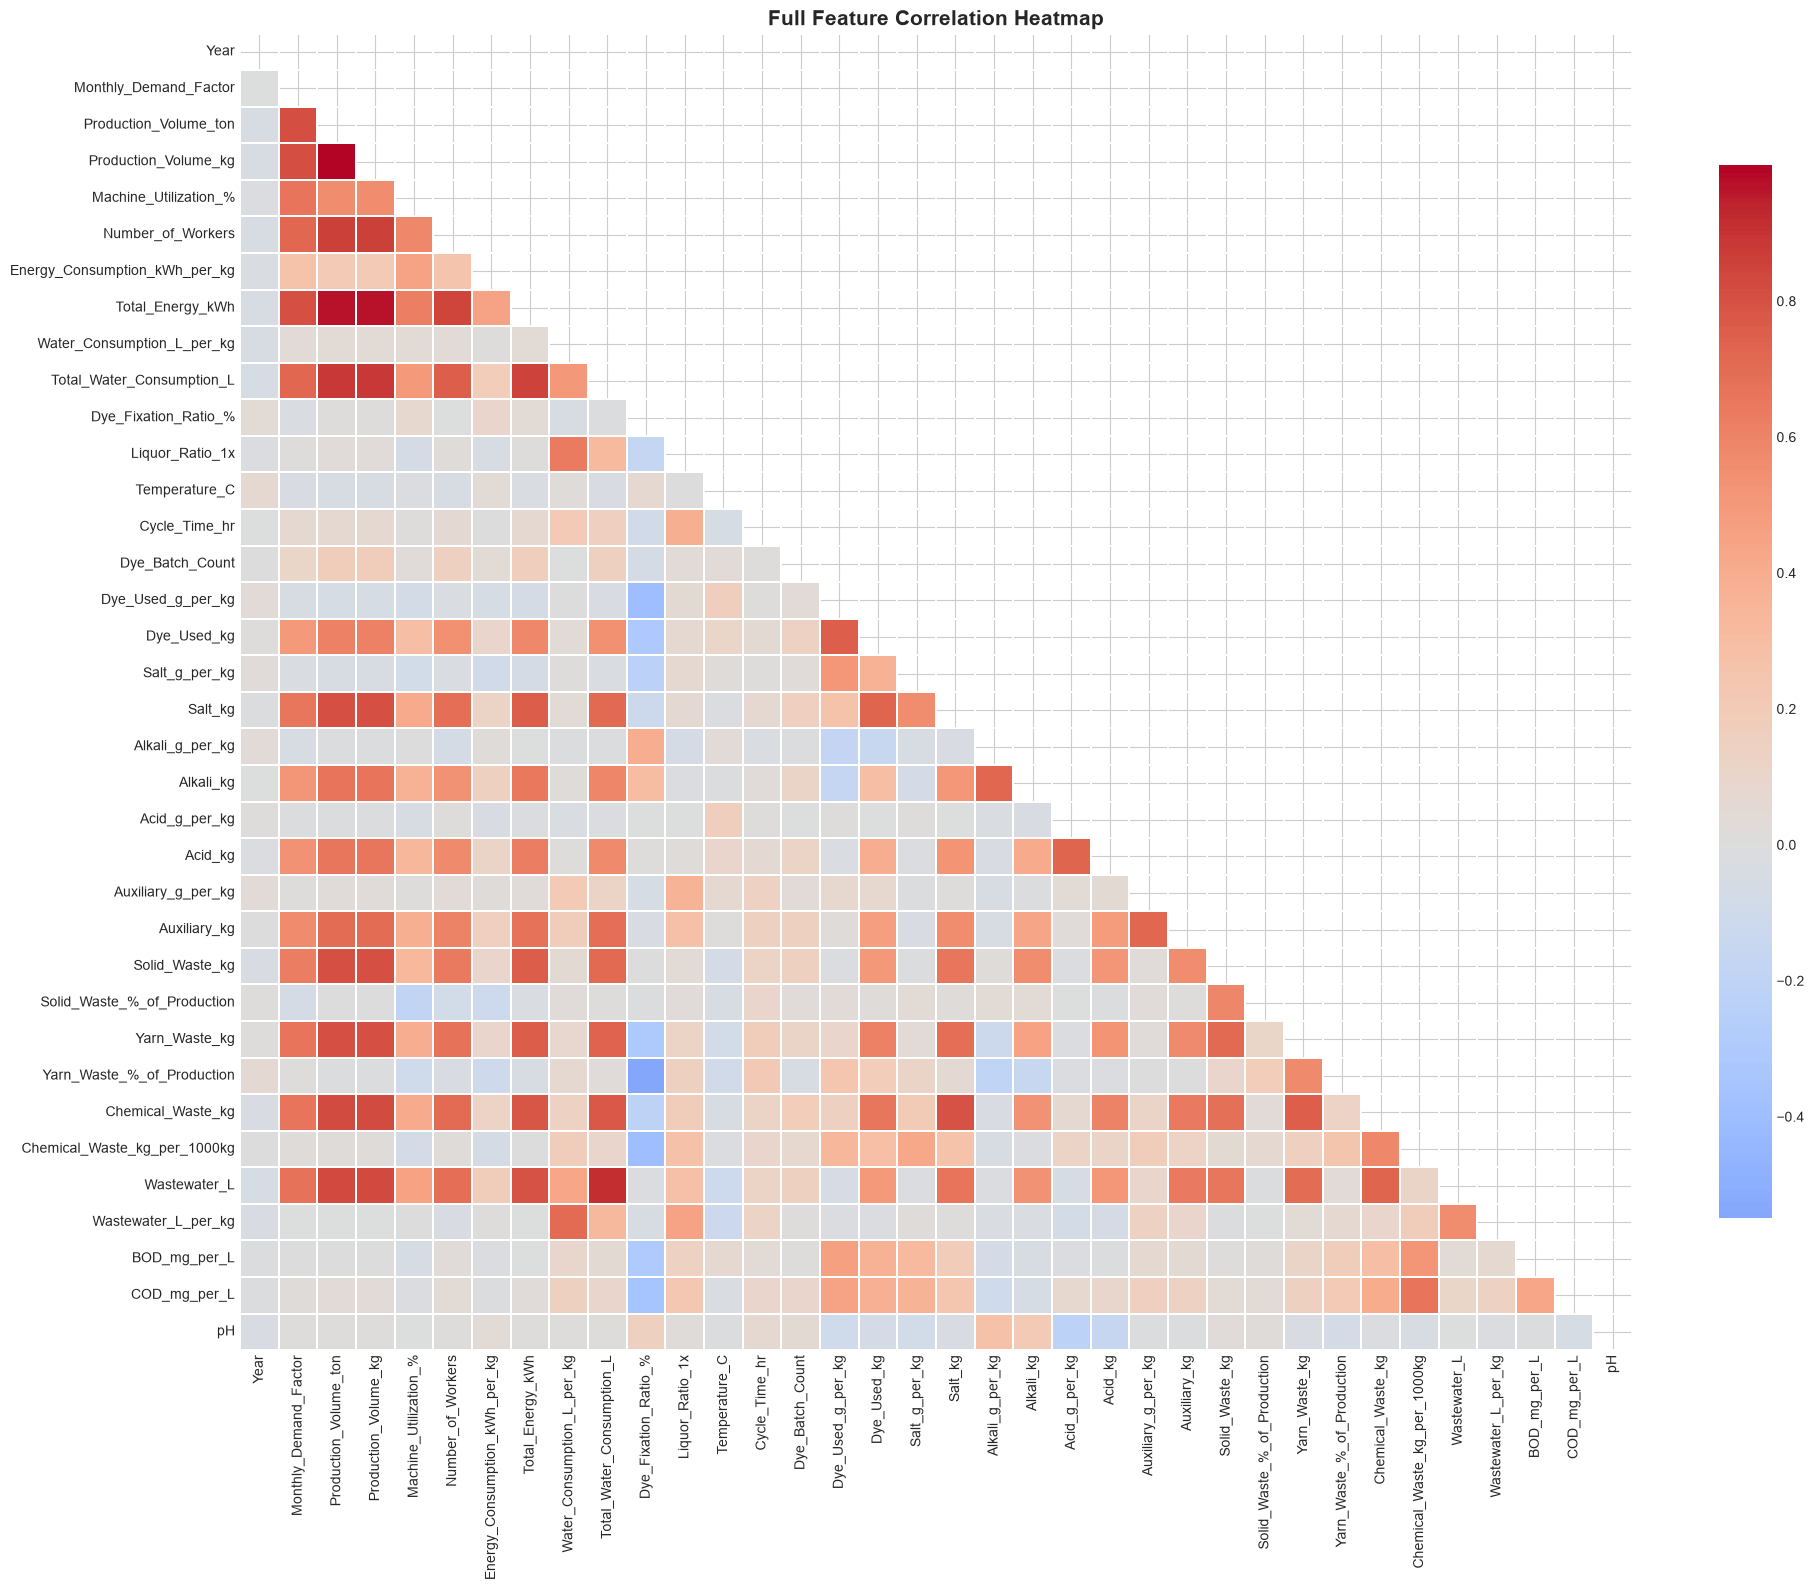

Saved: 04_full_correlation_heatmap.png


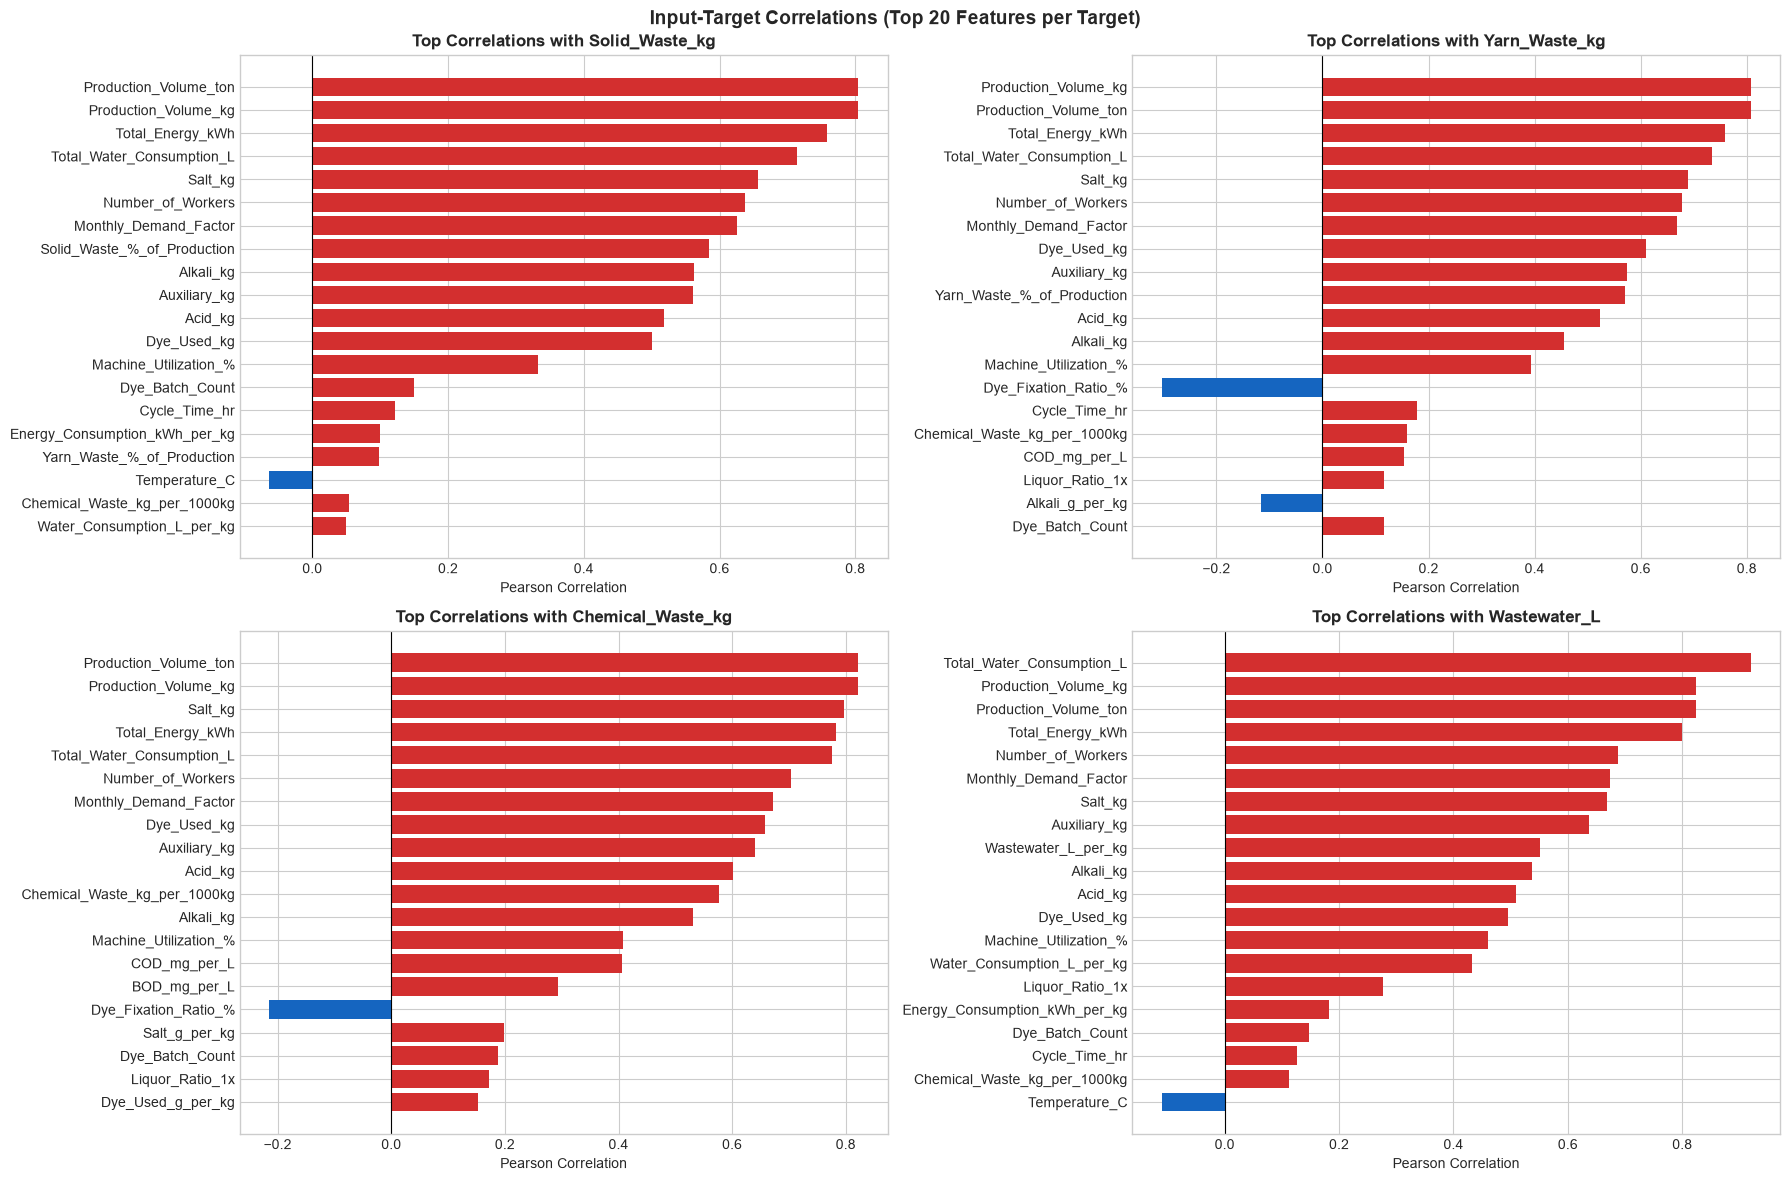

Saved: 05_input_target_correlations.png


In [10]:
# Data Exploration — Correlation Heatmap
numeric_cols = df_raw.select_dtypes(include=np.number).columns.tolist()
corr_matrix  = df_raw[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, fmt='.2f',
            cmap='coolwarm', center=0, linewidths=0.3,
            cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title("Full Feature Correlation Heatmap", fontsize=15, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/04_full_correlation_heatmap.png", dpi=150)
plt.show()
print("Saved: 04_full_correlation_heatmap.png")

# Correlation of inputs with each target
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for i, target in enumerate(TARGETS):
    row, col = divmod(i, 2)
    corr_with_target = corr_matrix[target].drop(TARGETS).sort_values(key=abs, ascending=False).head(20)
    colors_bar = ['#D32F2F' if v > 0 else '#1565C0' for v in corr_with_target.values]
    axes[row, col].barh(corr_with_target.index, corr_with_target.values, color=colors_bar)
    axes[row, col].axvline(0, color='black', linewidth=0.8)
    axes[row, col].set_title(f'Top Correlations with {target}', fontsize=12, fontweight='bold')
    axes[row, col].set_xlabel('Pearson Correlation')
    axes[row, col].invert_yaxis()

plt.suptitle("Input-Target Correlations (Top 20 Features per Target)", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/05_input_target_correlations.png", dpi=150)
plt.show()
print("Saved: 05_input_target_correlations.png")

## IMPROVEMENT 1 & 2 — Feature Engineering

### New modules are added:

| Group | Features | Reason |
|-------|----------|--------|
| **Cyclical encoding** | Month_Sin/Cos, Day_Sin/Cos, Quarter | Month 1 and 12 are adjacent — raw numbers make them far apart. Sin/cos wraps the cycle correctly. |
| **Interaction features** | Prod×DyeBatch, Prod×Acid, Prod×Salt, Prod×Alkali, Prod×Auxiliary, Chem_inputs_total | High production *and* many batches together cause disproportionately more waste than either alone. |
| **Physically motivated** | Fixation_loss_kg = (1 − Dye_Fixation%) × Dye_Used_kg | Unfixed dye does not go onto fabric — it becomes chemical waste. Models the mechanism directly. |
| **Ratio features** | Chem_per_litre, Energy_per_worker, Prod_per_worker | Normalised efficiency features capture operational intensity. |
| **Lag features** | _lag1, _lag7 for all 4 targets + Production | Yesterday's waste tells the model about shift patterns and batch queues not visible in raw process variables. |
| **Rolling features** | _roll7, _roll30, _std7 | 7-day and 30-day context + volatility. All use `.shift(1)` to **prevent look-ahead data leakage**. |

In [11]:
# CELL 9: IMPROVEMENT 1 & 2 — Feature Engineering
#         Cyclical Encoding + Interaction Features + Lag/Rolling
df = df_raw.sort_values('Date').copy().reset_index(drop=True)

# ── Cyclical time encoding ─────────────────────────────
months      = df['Date'].dt.month
day_of_week = df['Date'].dt.dayofweek

df['Month_Sin'] = np.sin(2 * np.pi * months / 12)
df['Month_Cos'] = np.cos(2 * np.pi * months / 12)
df['Day_Sin']   = np.sin(2 * np.pi * day_of_week / 7)
df['Day_Cos']   = np.cos(2 * np.pi * day_of_week / 7)
df['Quarter']   = df['Date'].dt.quarter

# ── Interaction features ──────────────────────────
df['Prod_x_DyeBatch']   = df['Production_Volume_kg'] * df['Dye_Batch_Count']
df['Prod_x_Acid']       = df['Production_Volume_kg'] * df['Acid_kg']
df['Prod_x_Salt']       = df['Production_Volume_kg'] * df['Salt_kg']
df['Prod_x_Alkali']     = df['Production_Volume_kg'] * df['Alkali_kg']
df['Prod_x_Auxiliary']  = df['Production_Volume_kg'] * df['Auxiliary_kg']
df['Chem_inputs_total'] = (df['Acid_kg'] + df['Salt_kg'] + df['Alkali_kg']
                           + df['Auxiliary_kg'] + df['Dye_Used_kg'])

# Physically motivated: unfixed dye → chemical waste
df['Fixation_loss_kg']  = (1 - df['Dye_Fixation_Ratio_%'] / 100) * df['Dye_Used_kg']
df['Chem_per_litre']    = df['Chem_inputs_total'] / (df['Total_Water_Consumption_L'] + 1)
df['Energy_per_worker'] = df['Total_Energy_kWh'] / (df['Number_of_Workers'] + 1)
df['Prod_per_worker']   = df['Production_Volume_kg'] / (df['Number_of_Workers'] + 1)

# ── Lag & rolling features ──
LAG_COLS = [
    ('Chemical_Waste_kg',    'chem'),
    ('Solid_Waste_kg',       'solid'),
    ('Yarn_Waste_kg',        'yarn'),
    ('Wastewater_L',         'water'),
    ('Production_Volume_kg', 'prod'),
]

def _add_lag_features(g):
    g = g.sort_values('Date').copy()
    for col, prefix in LAG_COLS:
        s = g[col].shift(1)
        g[f'{prefix}_lag1']   = s
        g[f'{prefix}_lag7']   = g[col].shift(7)
        g[f'{prefix}_roll7']  = s.rolling(7,  min_periods=1).mean()
        g[f'{prefix}_roll30'] = s.rolling(30, min_periods=1).mean()
        g[f'{prefix}_std7']   = s.rolling(7,  min_periods=1).std().fillna(0)
    return g

# Compute within each calendar year independently -> train (2023) and test (2024)
# never share lag information across the split boundary.
df = (df.groupby(df['Date'].dt.year, group_keys=False)
        .apply(_add_lag_features)
        .reset_index(drop=True))

# Drop rows with NaN from lag features (first 7 rows of EACH year)
df = df.dropna().reset_index(drop=True)

# ── Final feature list (dynamic — auto-includes all new features) ──
EXCL = (TARGETS
        + ['Solid_Waste_%_of_Production', 'Yarn_Waste_%_of_Production',
           'Chemical_Waste_kg_per_1000kg', 'Wastewater_L_per_kg',
           'Date', 'Day_Type', 'Year', 'Month'])
FEATURE_COLS = [c for c in df.columns if c not in EXCL]

print(" Feature engineering complete.")
print(f"   Original features : 23")
print(f"   New features added : {len(FEATURE_COLS) - 23}")
print(f"   Total features     : {len(FEATURE_COLS)}")
print("\nNew features added:")
original_set = {'Month_Sin','Month_Cos','Day_Sin','Day_Cos','Quarter',
                'Production_Volume_kg','Machine_Utilization_%','Number_of_Workers',
                'Total_Energy_kWh','Total_Water_Consumption_L','Dye_Fixation_Ratio_%',
                'Liquor_Ratio_1x','Temperature_C','Cycle_Time_hr','Dye_Batch_Count',
                'Dye_Used_kg','Salt_kg','Alkali_kg','Acid_kg','Auxiliary_kg',
                'BOD_mg_per_L','COD_mg_per_L','pH'}
for f in FEATURE_COLS:
    if f not in original_set:
        print(f"   + {f}")

 Feature engineering complete.
   Original features : 23
   New features added : 44
   Total features     : 67

New features added:
   + Monthly_Demand_Factor
   + Production_Volume_ton
   + Energy_Consumption_kWh_per_kg
   + Water_Consumption_L_per_kg
   + Dye_Used_g_per_kg
   + Salt_g_per_kg
   + Alkali_g_per_kg
   + Acid_g_per_kg
   + Auxiliary_g_per_kg
   + Prod_x_DyeBatch
   + Prod_x_Acid
   + Prod_x_Salt
   + Prod_x_Alkali
   + Prod_x_Auxiliary
   + Chem_inputs_total
   + Fixation_loss_kg
   + Chem_per_litre
   + Energy_per_worker
   + Prod_per_worker
   + chem_lag1
   + chem_lag7
   + chem_roll7
   + chem_roll30
   + chem_std7
   + solid_lag1
   + solid_lag7
   + solid_roll7
   + solid_roll30
   + solid_std7
   + yarn_lag1
   + yarn_lag7
   + yarn_roll7
   + yarn_roll30
   + yarn_std7
   + water_lag1
   + water_lag7
   + water_roll7
   + water_roll30
   + water_std7
   + prod_lag1
   + prod_lag7
   + prod_roll7
   + prod_roll30
   + prod_std7


In [12]:
# Train - Test
df_train = df[df['Date'].dt.year == 2023].copy()
df_test  = df[df['Date'].dt.year == 2024].copy()

X_train = df_train[FEATURE_COLS].reset_index(drop=True)
y_train = df_train[TARGETS].reset_index(drop=True)
X_test  = df_test[FEATURE_COLS].reset_index(drop=True)
y_test  = df_test[TARGETS].reset_index(drop=True)

print(f"Train set (2023): X={X_train.shape}, y={y_train.shape}")
print(f"Test  set (2024): X={X_test.shape},  y={y_test.shape}")
print(f"\n   NaN in X_train : {X_train.isnull().sum().sum()}")
print(f"   NaN in X_test  : {X_test.isnull().sum().sum()}")

Train set (2023): X=(358, 67), y=(358, 4)
Test  set (2024): X=(359, 67),  y=(359, 4)

   NaN in X_train : 0
   NaN in X_test  : 0


## IMPROVEMENT 3 — Skew Check (No Log Transform Needed)

**Decision rule:** a skew between **−0.5 and +0.5** is considered approximately normal for modelling. Applying a log transform to an already-normal distribution *distorts* it and can hurt performance, so we only transform when skew exceeds ±0.5.

In [13]:
# IMPROVEMENT 3 — Skew Check (no Log transform applied)
y_train_transformed = y_train.copy()
for t in LOG_TARGETS:
    y_train_transformed[t] = np.log1p(y_train[t])

print("Skew check — log transform decision per target:")
print("-" * 55)
for t in TARGETS:
    skew = y_train[t].skew()
    if t in LOG_TARGETS:
        print(f"  {t:<25}: {skew:.3f}  -> log transformed")
    else:
        print(f"  {t:<25}: {skew:.3f}  -> within +/-0.5, NOT transformed")

Skew check — log transform decision per target:
-------------------------------------------------------
  Solid_Waste_kg           : 0.461  -> within +/-0.5, NOT transformed
  Yarn_Waste_kg            : 0.474  -> within +/-0.5, NOT transformed
  Chemical_Waste_kg        : 0.350  -> within +/-0.5, NOT transformed
  Wastewater_L             : 0.250  -> within +/-0.5, NOT transformed


In [14]:
# Baseline XGBoost Model (Default Parameters)
xgb_base = XGBRegressor(
    n_estimators     = 300,
    max_depth        = 6,
    learning_rate    = 0.1,
    subsample        = 0.8,
    colsample_bytree = 0.8,
    random_state     = 42,
    n_jobs           = -1,
    verbosity        = 0,
)
model_base = MultiOutputRegressor(xgb_base, n_jobs=-1)
model_base.fit(X_train, y_train_transformed)

# Predict and reverse log transform where applied (none here)
y_pred_base_raw = pd.DataFrame(model_base.predict(X_test), columns=TARGETS)
y_pred_base = y_pred_base_raw.copy()
for t in LOG_TARGETS:
    y_pred_base[t] = np.expm1(y_pred_base_raw[t])

print("Baseline model trained.")
print("Baseline Test Performance")
for target in TARGETS:
    mae  = mean_absolute_error(y_test[target], y_pred_base[target])
    rmse = np.sqrt(mean_squared_error(y_test[target], y_pred_base[target]))
    r2   = r2_score(y_test[target], y_pred_base[target])
    mape = mean_absolute_percentage_error(y_test[target], y_pred_base[target]) * 100
    print(f"  {target:<25} MAE={mae:>10.2f}  RMSE={rmse:>10.2f}  R²={r2:.4f}  MAPE={mape:.2f}%")

Baseline model trained.
Baseline Test Performance
  Solid_Waste_kg            MAE=    249.85  RMSE=    320.08  R²=0.5988  MAPE=12.18%
  Yarn_Waste_kg             MAE=     99.75  RMSE=    124.05  R²=0.6789  MAPE=11.53%
  Chemical_Waste_kg         MAE=    318.85  RMSE=    407.16  R²=0.7714  MAPE=9.50%
  Wastewater_L              MAE=  48350.88  RMSE=  61269.89  R²=0.8165  MAPE=8.80%


## 🆕 IMPROVEMENT 4 — Walk-Forward Time-Series Cross-Validation

### Why NOT regular KFold?

The data is daily time-series (2023–2024). Regular `KFold(shuffle=True)` randomly mixes past and future rows — this means the model can accidentally train on future data to predict past data. That is **data leakage** and produces artificially optimistic R² scores.

**Walk-Forward CV** always trains on the past and tests on the future — exactly how a real deployed model would operate.

```
Fold 1: Train [Jan-Apr 2023]  →  Test [Jun-Jul 2023]  (gap=7 days)
Fold 2: Train [Jan-Jul 2023]  →  Test [Sep-Oct 2023]
Fold 3: Train [Jan-Oct 2023]  →  Test [Dec 2023]
...
```

The `gap=7` is important — it prevents the 7-day lag features from bleeding across the fold boundary.

---

**Per-target tuning (Option B):** rather than tuning on a single target and reusing those parameters for all four, the grid search is run **separately for each target**. Each waste stream then gets the hyperparameters that generalise best for *it* under walk-forward CV. This avoids the situation where one target's optimal settings hurt another (e.g. settings best for solid waste underperforming on wastewater).

In [15]:
# ============================================================
# Walk-Forward CV + Per-Target Hyperparameter Tuning
# NOTE: This may take 15-40 minutes (4 separate grid searches).
#
# REVISED TUNING PROTOCOL (identical structure to the Random Forest notebook):
#   - n_splits=3 (was 5): with only ~358 training rows, 5 splits produced
#     tiny early folds (56-115 rows) whose scores did NOT transfer to the
#     full-data fit. 3 splits give larger, more representative folds.
#   - scoring='neg_mean_absolute_error' (was 'r2'): R2 is extremely noisy on
#     ~60-row validation folds and was nearly uncorrelated with test R2.
#     MAE is a far more stable selection signal on small temporal folds.
#   - Grid: max_depth capped at 4 (was up to 7) to stop overfitting on this
#     small/smooth dataset, plus min_child_weight and reg_lambda added as
#     XGBoost's native regularizers (the original grid had none).
# ============================================================
tscv = TimeSeriesSplit(n_splits=3, gap=7)   # gap=7 prevents lag feature leakage

param_grid = {
    'max_depth'       : [2, 3, 4],          # capped: depth 5-7 overfit n=358
    'learning_rate'   : [0.03, 0.05, 0.1],
    'n_estimators'    : [400, 700],
    'min_child_weight': [3, 5, 10],         # NEW regularizer (min samples per leaf)
    'subsample'       : [0.8, 1.0],
    'colsample_bytree': [0.7, 0.9],
    'reg_lambda'      : [1.0, 5.0],         # NEW L2 regularization
}

print("\U0001f3f3 Running Walk-Forward GridSearchCV SEPARATELY for each target...")
print("   Each target gets its own best hyperparameters (Option B).")
print("   CV = TimeSeriesSplit(n_splits=3, gap=7); scoring = MAE (stable on small folds).\n")

best_params_per_target = {}
cv_score_per_target    = {}

for target in TARGETS:
    print(f"   -> Tuning: {target} ...")
    gs = GridSearchCV(
        XGBRegressor(random_state=42, n_jobs=-1, verbosity=0),
        param_grid,
        scoring='neg_mean_absolute_error',   # MAE: far less noisy than r2 on tiny folds
        cv=tscv,            # walk-forward, NOT random KFold
        n_jobs=-1,
        verbose=0,
        refit=True
    )
    gs.fit(X_train, y_train_transformed[target])
    best_params_per_target[target] = gs.best_params_
    cv_score_per_target[target]    = gs.best_score_   # this is -MAE (higher = better)
    print(f"        best CV score (neg-MAE) = {gs.best_score_:.4f}")
    print(f"        best params = {gs.best_params_}\n")

# Keep a single 'best_params' for any legacy reference (uses first target).
best_params = best_params_per_target[TARGETS[0]]

print("Per-target tuning complete. Summary:")
print("-" * 60)
for target in TARGETS:
    print(f"  {target:<25}: CV neg-MAE={cv_score_per_target[target]:.4f}")


🏳 Running Walk-Forward GridSearchCV SEPARATELY for each target...
   Each target gets its own best hyperparameters (Option B).
   CV = TimeSeriesSplit(n_splits=3, gap=7); scoring = MAE (stable on small folds).

   -> Tuning: Solid_Waste_kg ...
        best CV score (neg-MAE) = -282.0021
        best params = {'colsample_bytree': 0.9, 'learning_rate': 0.03, 'max_depth': 2, 'min_child_weight': 3, 'n_estimators': 700, 'reg_lambda': 5.0, 'subsample': 0.8}

   -> Tuning: Yarn_Waste_kg ...
        best CV score (neg-MAE) = -109.1227
        best params = {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 5, 'n_estimators': 700, 'reg_lambda': 1.0, 'subsample': 0.8}

   -> Tuning: Chemical_Waste_kg ...
        best CV score (neg-MAE) = -335.8455
        best params = {'colsample_bytree': 0.9, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 10, 'n_estimators': 700, 'reg_lambda': 1.0, 'subsample': 0.8}

   -> Tuning: Wastewater_L ...
        best CV s

In [16]:
# Final Tuned Model - Per-Target Training & Prediction
class PerTargetXGB:
    """Trains one XGBRegressor per target, each with its OWN best params.
    Exposes .estimators_ (in TARGETS order) so it is a drop-in replacement
    for MultiOutputRegressor in the downstream cells."""
    def __init__(self, params_per_target, targets):
        self.params_per_target = params_per_target
        self.targets = targets
        self.estimators_ = []

    def fit(self, X, Y):
        self.estimators_ = []
        for t in self.targets:
            est = XGBRegressor(**self.params_per_target[t],
                               random_state=42, n_jobs=-1, verbosity=0)
            est.fit(X, Y[t])
            self.estimators_.append(est)
        return self

    def predict(self, X):
        preds = [est.predict(X) for est in self.estimators_]
        return np.column_stack(preds)


model_final = PerTargetXGB(best_params_per_target, TARGETS)
model_final.fit(X_train, y_train_transformed)

# Predict - reverse log transform only if any LOG_TARGETS (empty here)
y_pred_raw = pd.DataFrame(model_final.predict(X_test), columns=TARGETS)
y_pred_df  = y_pred_raw.copy()
for t in LOG_TARGETS:
    y_pred_df[t] = np.expm1(y_pred_raw[t])

print("Per-target tuned XGBoost model trained and predictions made on 2024 test data.")
print("   Each target used its own optimised hyperparameters.")

Per-target tuned XGBoost model trained and predictions made on 2024 test data.
   Each target used its own optimised hyperparameters.


In [17]:
# Model Evaluation — Full Metrics Table
metrics_rows = []
print("=" * 80)
print(f"{'Target':<30} {'MAE':>9} {'RMSE':>10} {'R²':>8} {'MAPE%':>8}")
print("=" * 80)

for target in TARGETS:
    mae  = mean_absolute_error(y_test[target], y_pred_df[target])
    mse  = mean_squared_error(y_test[target], y_pred_df[target])
    rmse = np.sqrt(mse)
    r2   = r2_score(y_test[target], y_pred_df[target])
    mape = mean_absolute_percentage_error(y_test[target], y_pred_df[target]) * 100
    metrics_rows.append({'Target': target, 'MAE': round(mae, 3),
                         'MSE': round(mse, 3), 'RMSE': round(rmse, 3),
                         'R2': round(r2, 4), 'MAPE_%': round(mape, 2)})
    print(f"  {target:<28} {mae:>10.3f} {rmse:>10.3f} {r2:>8.4f} {mape:>7.2f}%")
print("=" * 80)

metrics_df = pd.DataFrame(metrics_rows)
print("Full Metrics DataFrame:")
display(metrics_df)
metrics_df.to_csv(f"{OUTPUT_DIR}/model_metrics_xgb.csv", index=False)
print(f" Metrics saved to: {OUTPUT_DIR}/model_metrics_xgb.csv")

Target                               MAE       RMSE       R²    MAPE%
  Solid_Waste_kg                  252.734    323.462   0.5903   12.25%
  Yarn_Waste_kg                    99.215    122.681   0.6859   11.40%
  Chemical_Waste_kg               312.274    389.104   0.7912    9.29%
  Wastewater_L                  50574.959  63548.702   0.8026    9.15%
Full Metrics DataFrame:


,Target,MAE,MSE,RMSE,R2,MAPE_%
0,Solid_Waste_kg,252.734,1.046275e+05,323.462,0.5903,12.25
1,Yarn_Waste_kg,99.215,1.505055e+04,122.681,0.6859,11.40
2,Chemical_Waste_kg,312.274,1.514016e+05,389.104,0.7912,9.29
3,Wastewater_L,50574.959,4.038438e+09,63548.702,0.8026,9.15


 Metrics saved to: output_figures_xgb/model_metrics_xgb.csv


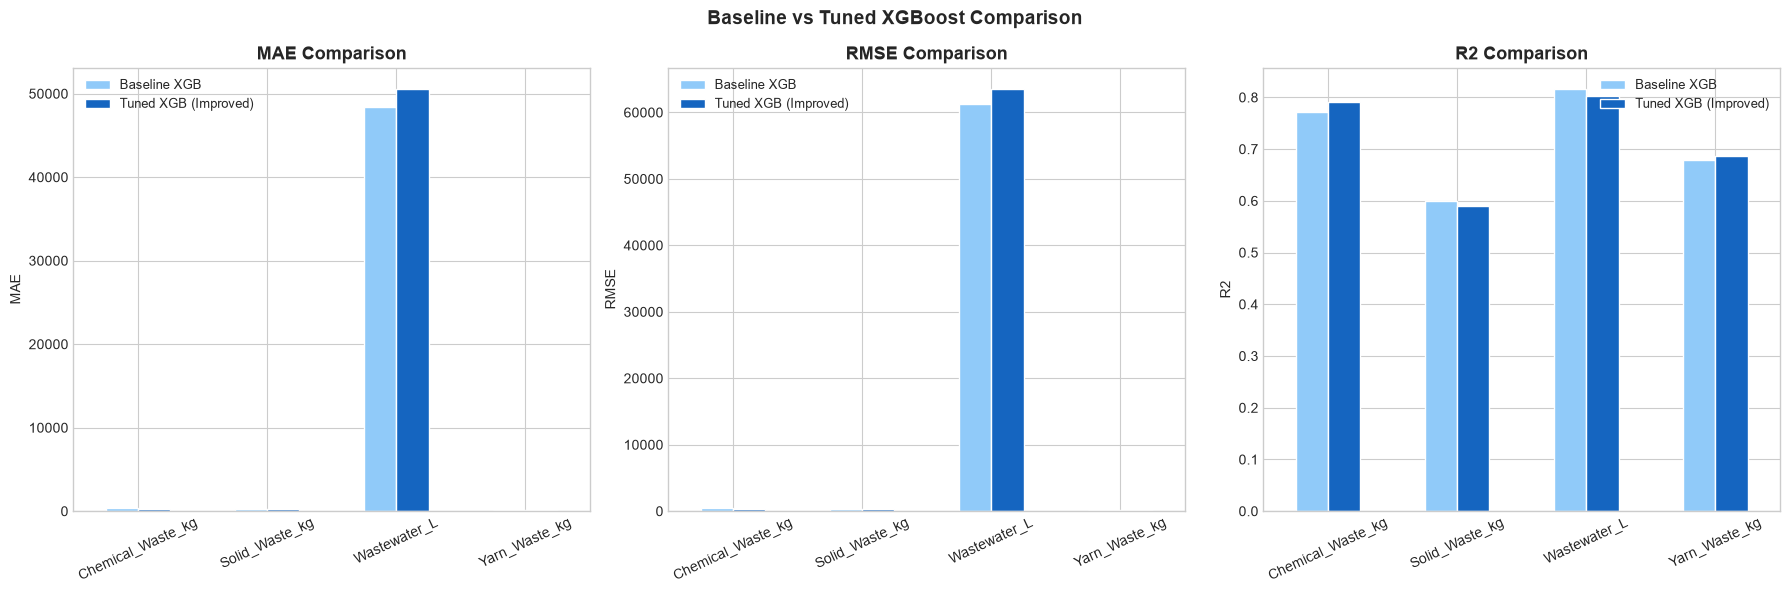

Saved: 06_baseline_vs_tuned_xgb.png


In [18]:
# Metrics Comparison — Baseline vs Tuned
metrics_base_rows, metrics_tuned_rows = [], []
for target in TARGETS:
    metrics_base_rows.append({
        'Target': target,
        'MAE' : mean_absolute_error(y_test[target], y_pred_base[target]),
        'RMSE': np.sqrt(mean_squared_error(y_test[target], y_pred_base[target])),
        'R2'  : r2_score(y_test[target], y_pred_base[target]),
        'Model': 'Baseline XGB'
    })
    metrics_tuned_rows.append({
        'Target': target,
        'MAE' : mean_absolute_error(y_test[target], y_pred_df[target]),
        'RMSE': np.sqrt(mean_squared_error(y_test[target], y_pred_df[target])),
        'R2'  : r2_score(y_test[target], y_pred_df[target]),
        'Model': 'Tuned XGB (Improved)'
    })

compare_df = pd.DataFrame(metrics_base_rows + metrics_tuned_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    pivot = compare_df.pivot(index='Target', columns='Model', values=metric)
    pivot.plot(kind='bar', ax=ax, color=['#90CAF9', '#1565C0'], edgecolor='white')
    ax.set_title(f'{metric} Comparison', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=25)
    ax.legend(fontsize=9)

plt.suptitle("Baseline vs Tuned XGBoost Comparison", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/06_baseline_vs_tuned_xgb.png", dpi=150)
plt.show()
print("Saved: 06_baseline_vs_tuned_xgb.png")

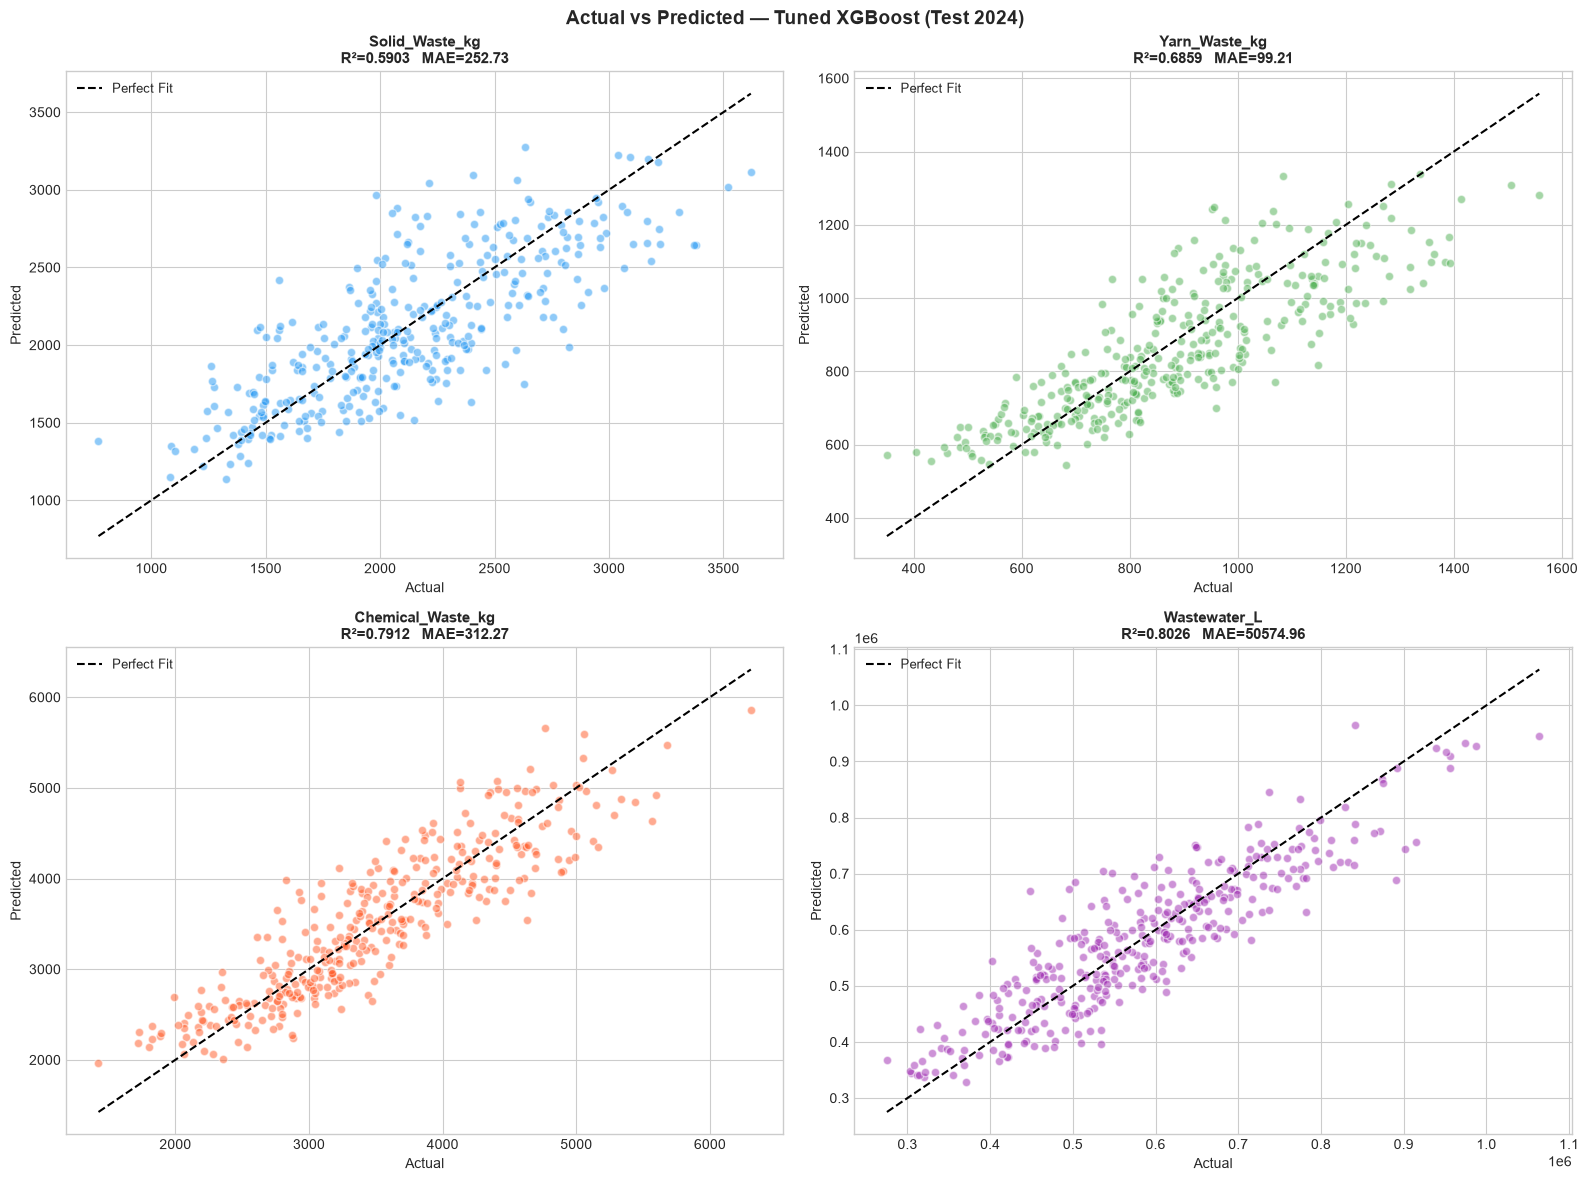

Saved: 07_actual_vs_predicted_scatter.png


In [19]:
# Visual — Actual vs Predicted Scatter (All 4 Targets)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    row, col = divmod(i, 2)
    ax = axes[row, col]

    y_true_col = y_test[target].values
    y_pred_col = y_pred_df[target].values

    ax.scatter(y_true_col, y_pred_col, alpha=0.5, color=color, edgecolors='white')
    min_val = min(y_true_col.min(), y_pred_col.min())
    max_val = max(y_true_col.max(), y_pred_col.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='Perfect Fit')

    r2  = r2_score(y_true_col, y_pred_col)
    mae = mean_absolute_error(y_true_col, y_pred_col)
    ax.set_title(f'{target}\nR²={r2:.4f}   MAE={mae:.2f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.legend(fontsize=9)

plt.suptitle("Actual vs Predicted — Tuned XGBoost (Test 2024)", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/07_actual_vs_predicted_scatter.png", dpi=150)
plt.show()
print("Saved: 07_actual_vs_predicted_scatter.png")

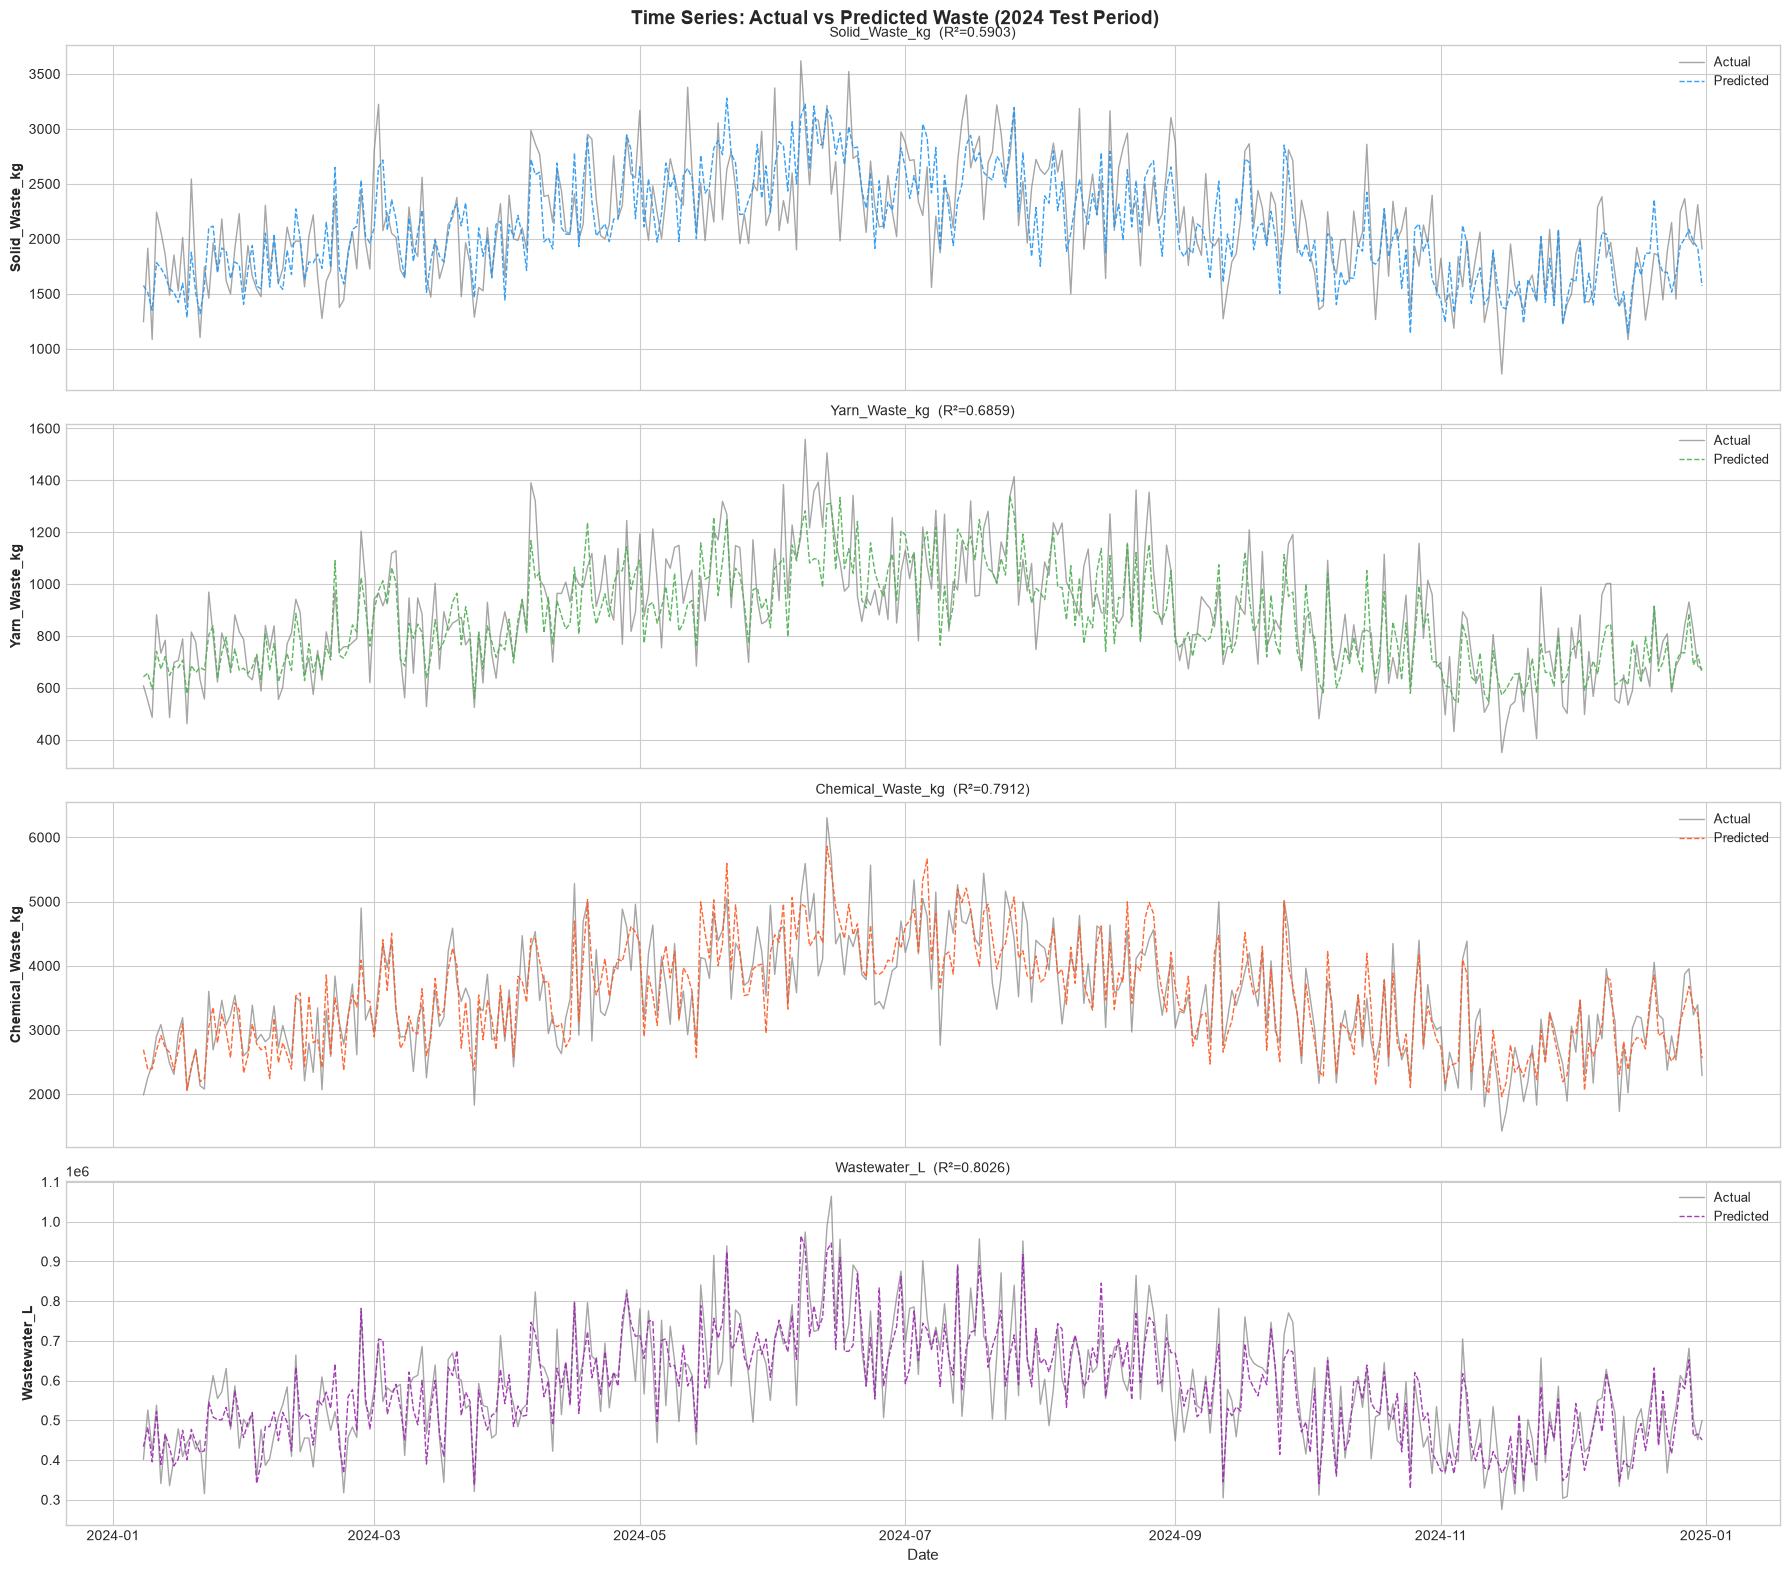

Saved: 08_timeseries_actual_vs_predicted.png


In [20]:
# Visual — Predicted vs Actual Time Series (2024)
date_test = df_test['Date'].reset_index(drop=True)

fig, axes = plt.subplots(4, 1, figsize=(18, 16), sharex=True)
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    axes[i].plot(date_test, y_test[target].values,    color='grey', linewidth=1,
                 label='Actual', alpha=0.7)
    axes[i].plot(date_test, y_pred_df[target].values, color=color, linewidth=1,
                 label='Predicted', alpha=0.9, linestyle='--')
    axes[i].set_ylabel(target, fontsize=10, fontweight='bold')
    axes[i].legend(fontsize=9, loc='upper right')
    r2 = r2_score(y_test[target], y_pred_df[target])
    axes[i].set_title(f'{target}  (R²={r2:.4f})', fontsize=10)

plt.suptitle("Time Series: Actual vs Predicted Waste (2024 Test Period)",
             fontsize=14, fontweight='bold')
plt.xlabel("Date", fontsize=11)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/08_timeseries_actual_vs_predicted.png", dpi=150)
plt.show()
print("Saved: 08_timeseries_actual_vs_predicted.png")

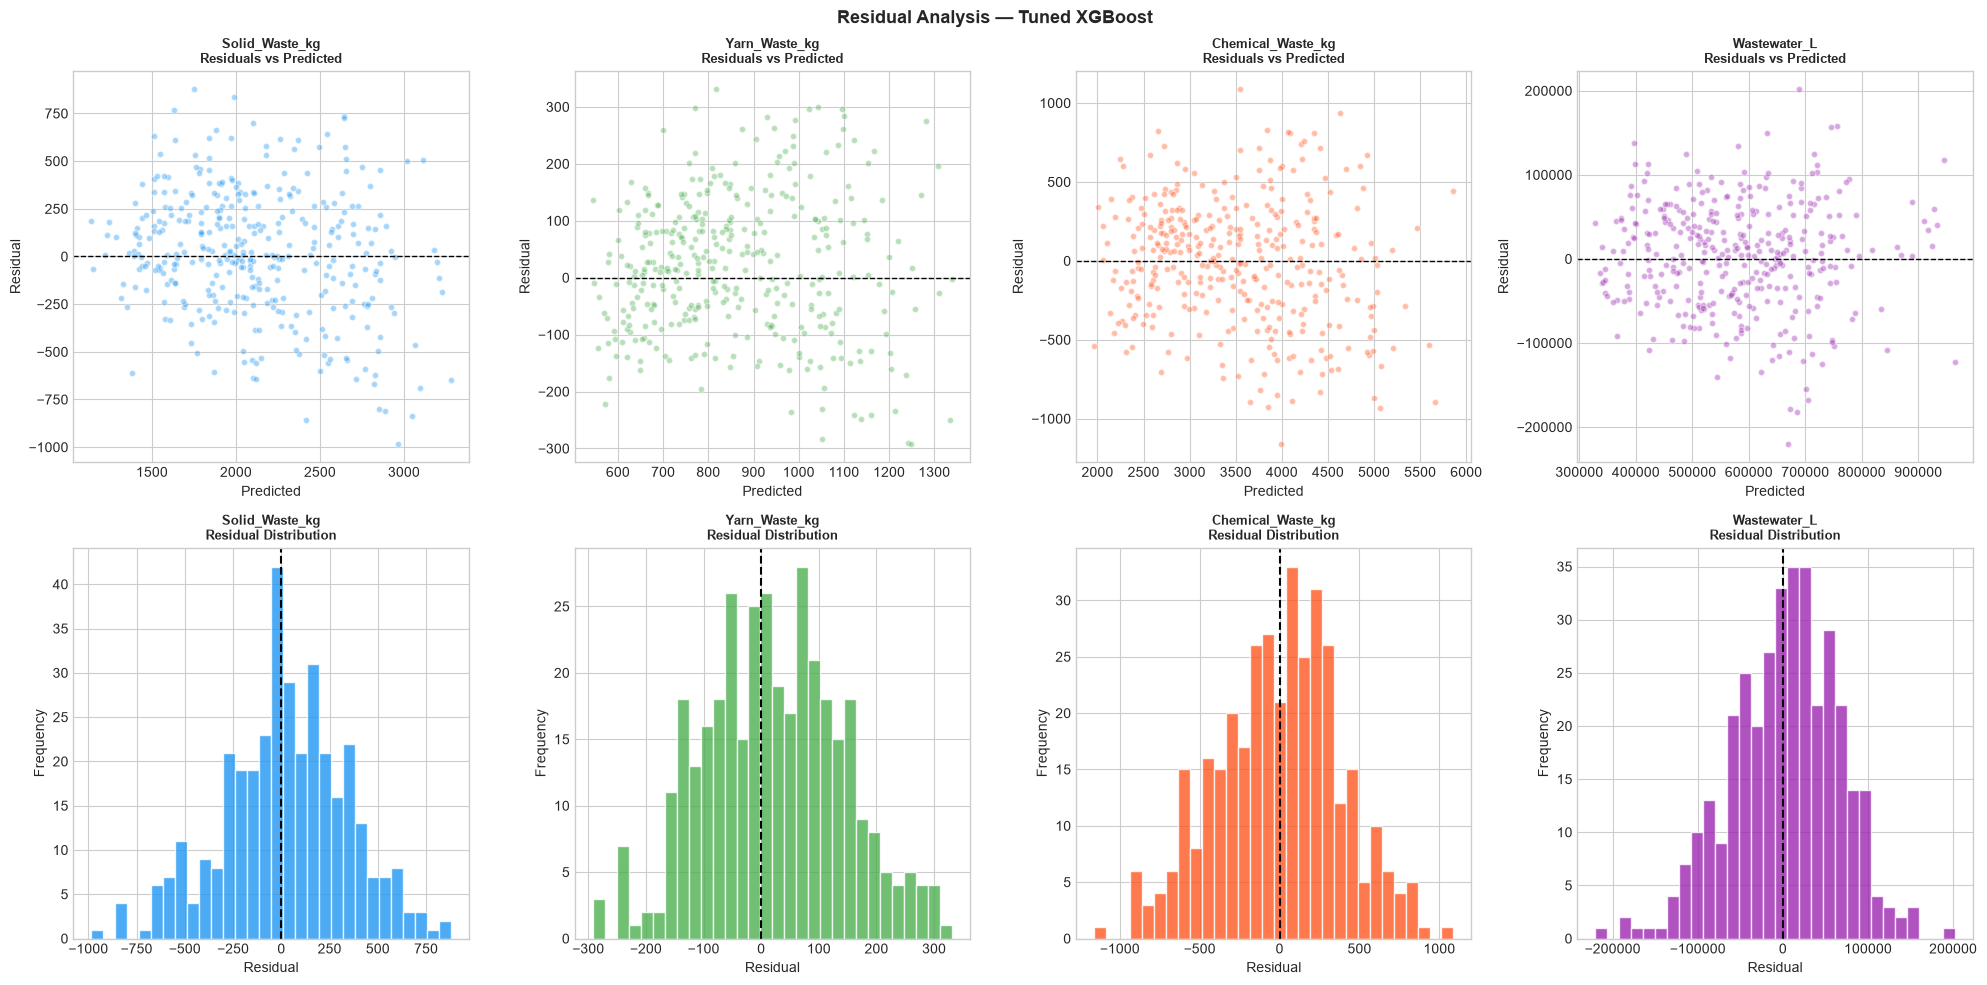

Saved: 09_residual_analysis.png


In [21]:
# Residual Analysis
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    residuals = y_test[target].values - y_pred_df[target].values

    axes[0, i].scatter(y_pred_df[target].values, residuals, alpha=0.4, color=color, edgecolors='white', s=20)
    axes[0, i].axhline(0, color='black', linewidth=1, linestyle='--')
    axes[0, i].set_title(f'{target}\nResiduals vs Predicted', fontsize=9, fontweight='bold')
    axes[0, i].set_xlabel('Predicted')
    axes[0, i].set_ylabel('Residual')

    axes[1, i].hist(residuals, bins=30, color=color, edgecolor='white', alpha=0.8)
    axes[1, i].axvline(0, color='black', linewidth=1.5, linestyle='--')
    axes[1, i].set_title(f'{target}\nResidual Distribution', fontsize=9, fontweight='bold')
    axes[1, i].set_xlabel('Residual')
    axes[1, i].set_ylabel('Frequency')

plt.suptitle("Residual Analysis — Tuned XGBoost", fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/09_residual_analysis.png", dpi=150)
plt.show()
print("Saved: 09_residual_analysis.png")

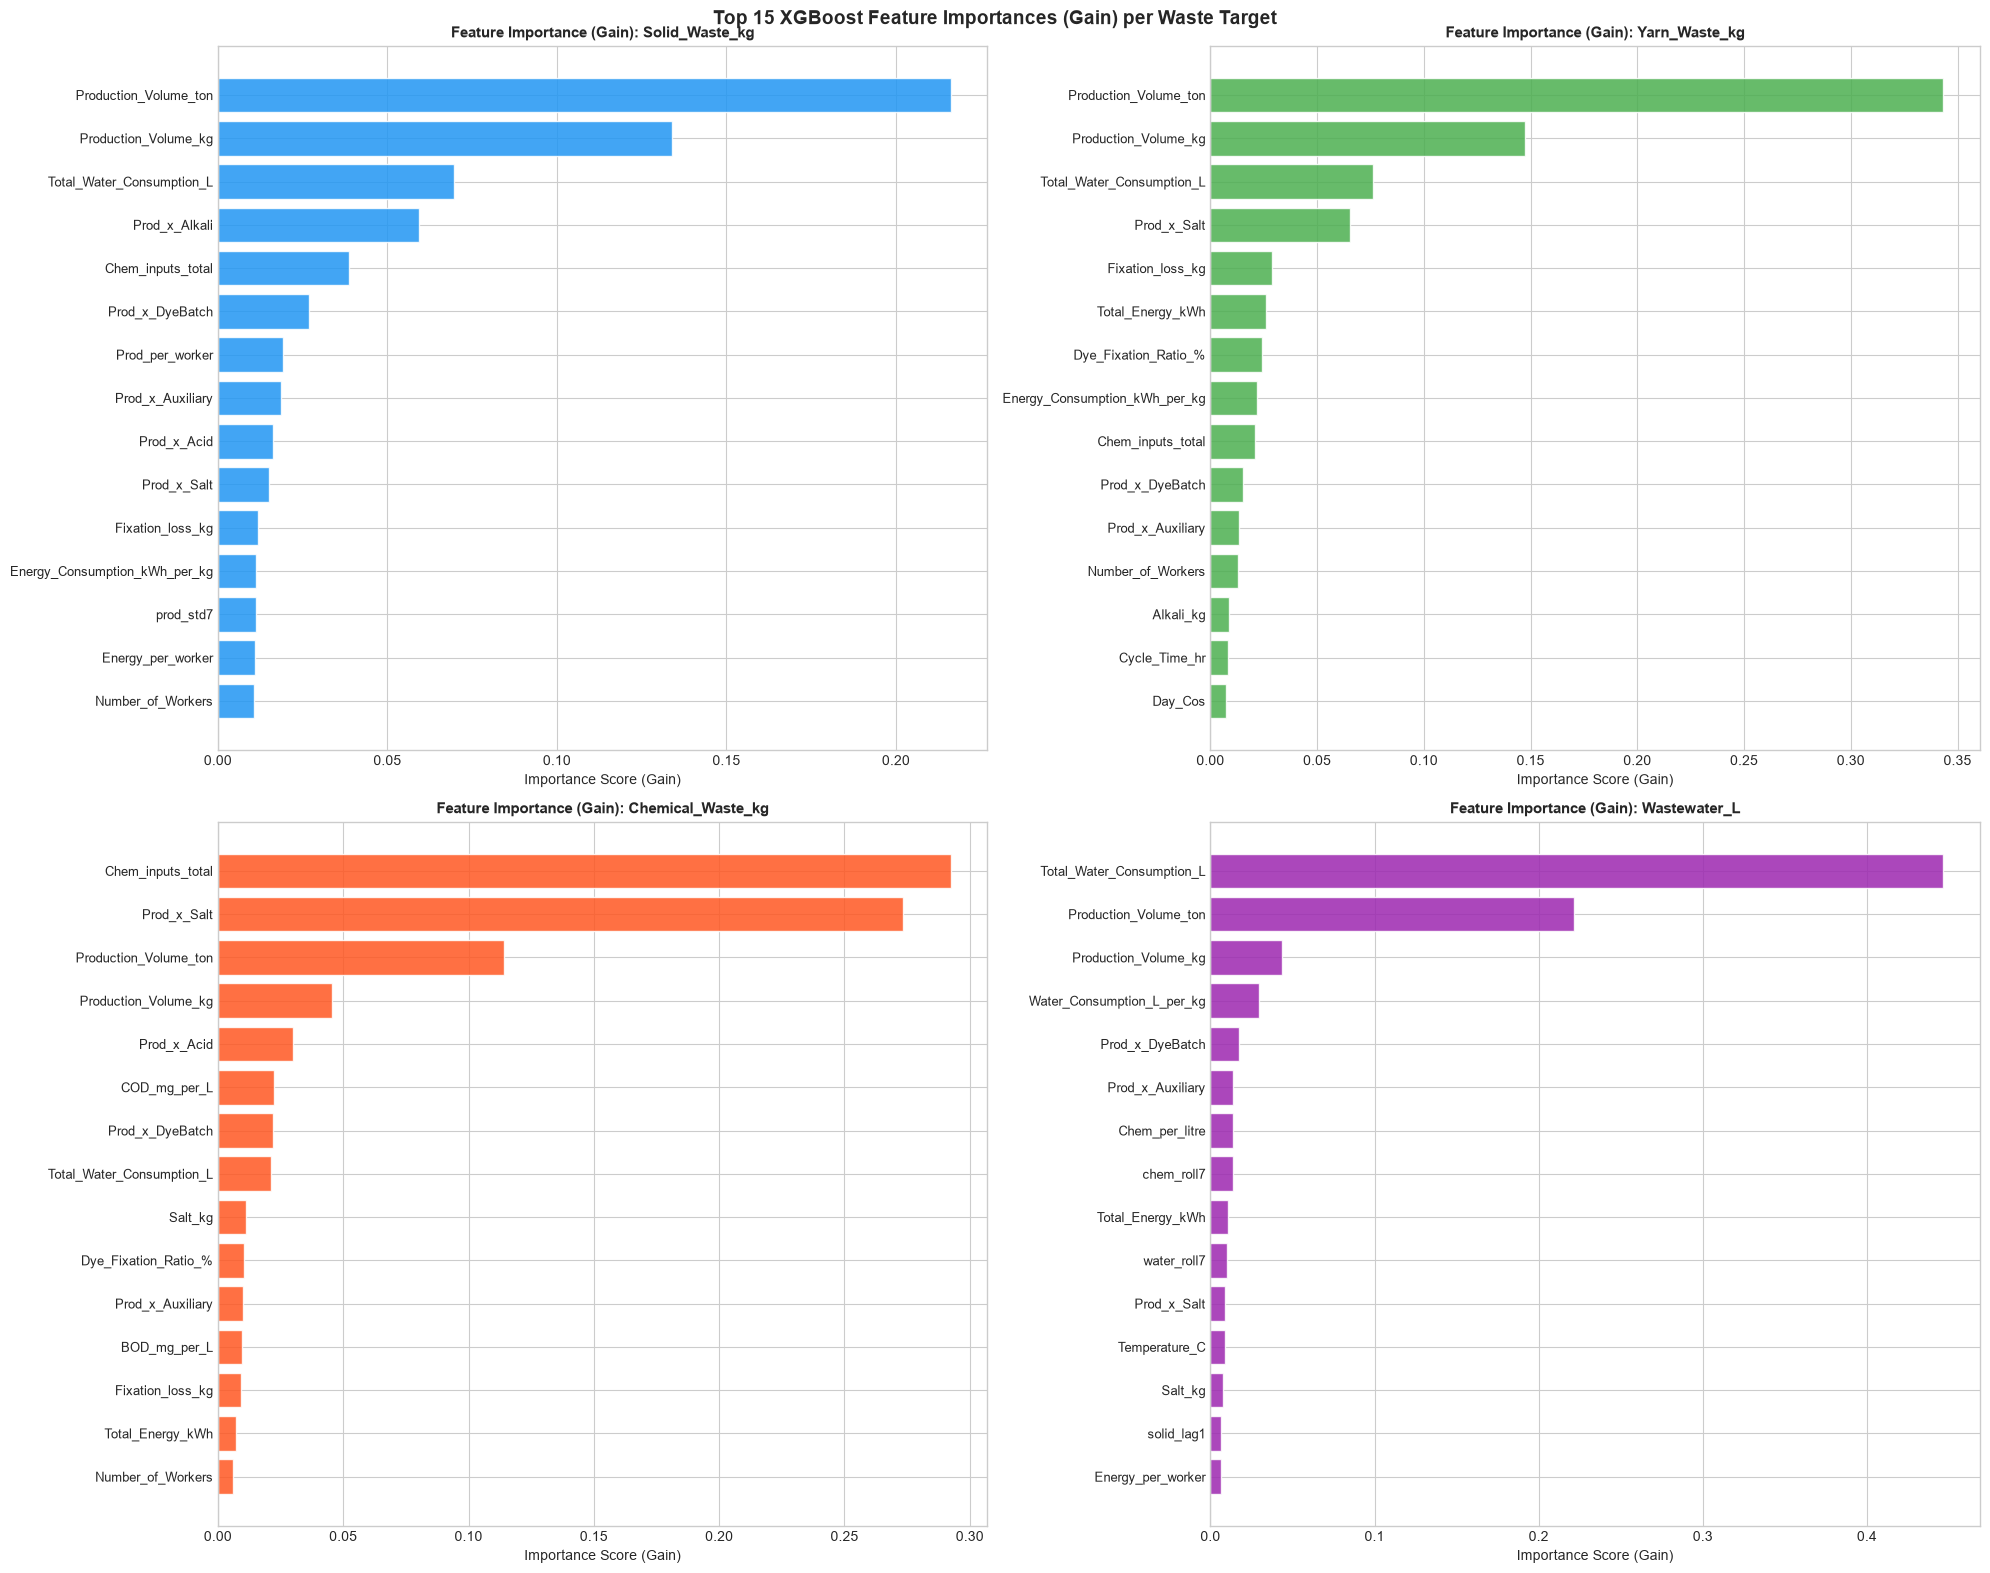

Saved: 10_feature_importance_per_target.png


In [22]:
# XGBoost Native Feature Importance (Gain) — Per Target
# XGBoost exposes importance_type: 'gain' (default), 'weight', 'cover'
# 'gain' = average gain of splits using the feature → most informative
fig, axes = plt.subplots(2, 2, figsize=(20, 16))
feature_importance_dict = {}

for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    estimator   = model_final.estimators_[i]          # XGBRegressor for this target
    importances = estimator.feature_importances_       # gain-based by default
    indices     = np.argsort(importances)[::-1]
    feature_importance_dict[target] = pd.Series(importances, index=FEATURE_COLS)

    row, col = divmod(i, 2)
    ax = axes[row, col]
    top_n = 15
    top_feats = [FEATURE_COLS[j] for j in indices[:top_n]]
    top_imp   = importances[indices[:top_n]]

    ax.barh(range(top_n), top_imp[::-1], color=color, edgecolor='white', alpha=0.85)
    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_feats[::-1], fontsize=9)
    ax.set_xlabel('Importance Score (Gain)', fontsize=10)
    ax.set_title(f'Feature Importance (Gain): {target}', fontsize=11, fontweight='bold')

plt.suptitle("Top 15 XGBoost Feature Importances (Gain) per Waste Target", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/10_feature_importance_per_target.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: 10_feature_importance_per_target.png")

Computing permutation importance (may take ~1-2 minutes)...
   Done: Solid_Waste_kg
   Done: Yarn_Waste_kg
   Done: Chemical_Waste_kg
   Done: Wastewater_L


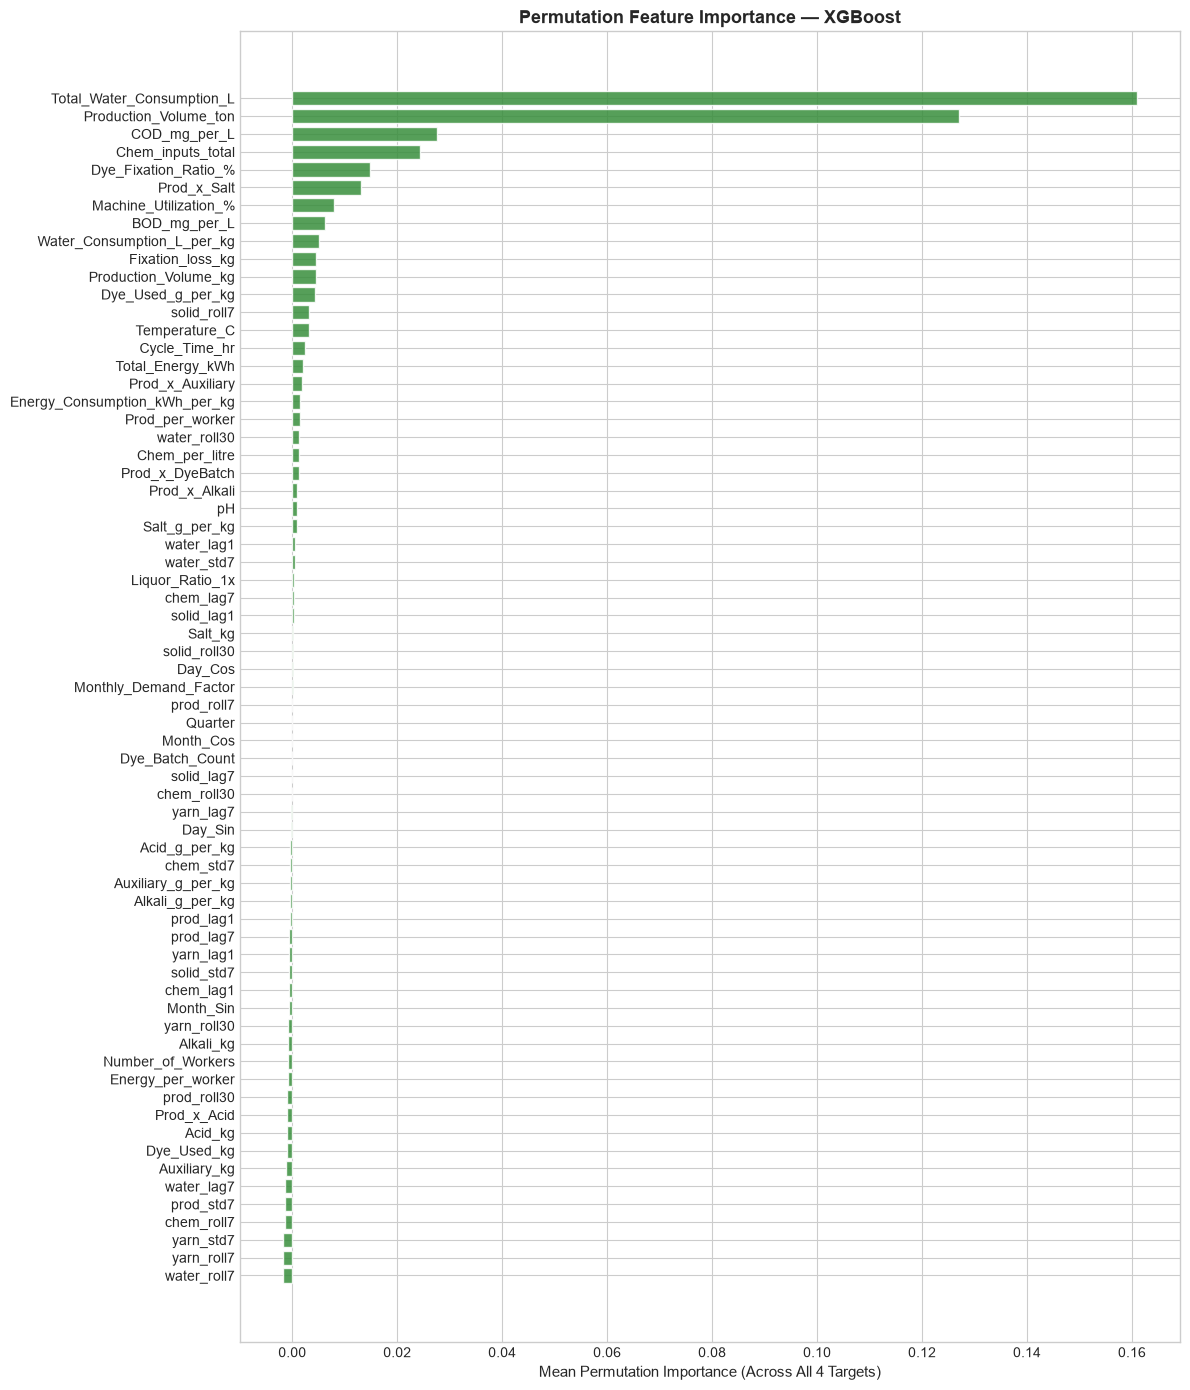

Saved: 13_permutation_importance.png


In [23]:
# ============================================================
# CELL 23: Permutation Feature Importance (Mean Across All Targets)
# ============================================================
# Permutation importance is unbiased for correlated/high-cardinality features.
# Computed on the test set for each target, then averaged.
print("Computing permutation importance (may take ~1-2 minutes)...")

perm_imp_dict = {}
for i, target in enumerate(TARGETS):
    estimator = model_final.estimators_[i]
    y_eval    = (np.log1p(y_test[target].values)
                 if target in LOG_TARGETS else y_test[target].values)
    result    = permutation_importance(estimator, X_test, y_eval,
                                        n_repeats=10, random_state=42, n_jobs=-1)
    perm_imp_dict[target] = pd.Series(result.importances_mean, index=FEATURE_COLS)
    print(f"   Done: {target}")

perm_df   = pd.DataFrame(perm_imp_dict)
perm_mean = perm_df.mean(axis=1).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 14))
ax.barh(perm_mean.index[::-1], perm_mean.values[::-1],
        color='#388E3C', edgecolor='white', alpha=0.85)
ax.set_xlabel('Mean Permutation Importance (Across All 4 Targets)', fontsize=11)
ax.set_title('Permutation Feature Importance — XGBoost', fontsize=13, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/13_permutation_importance.png", dpi=150, bbox_inches='tight')
plt.show()
print("Saved: 13_permutation_importance.png")

Computing SHAP values (may take 1-3 minutes)...
   SHAP done: Solid_Waste_kg
   SHAP done: Yarn_Waste_kg
   SHAP done: Chemical_Waste_kg
   SHAP done: Wastewater_L


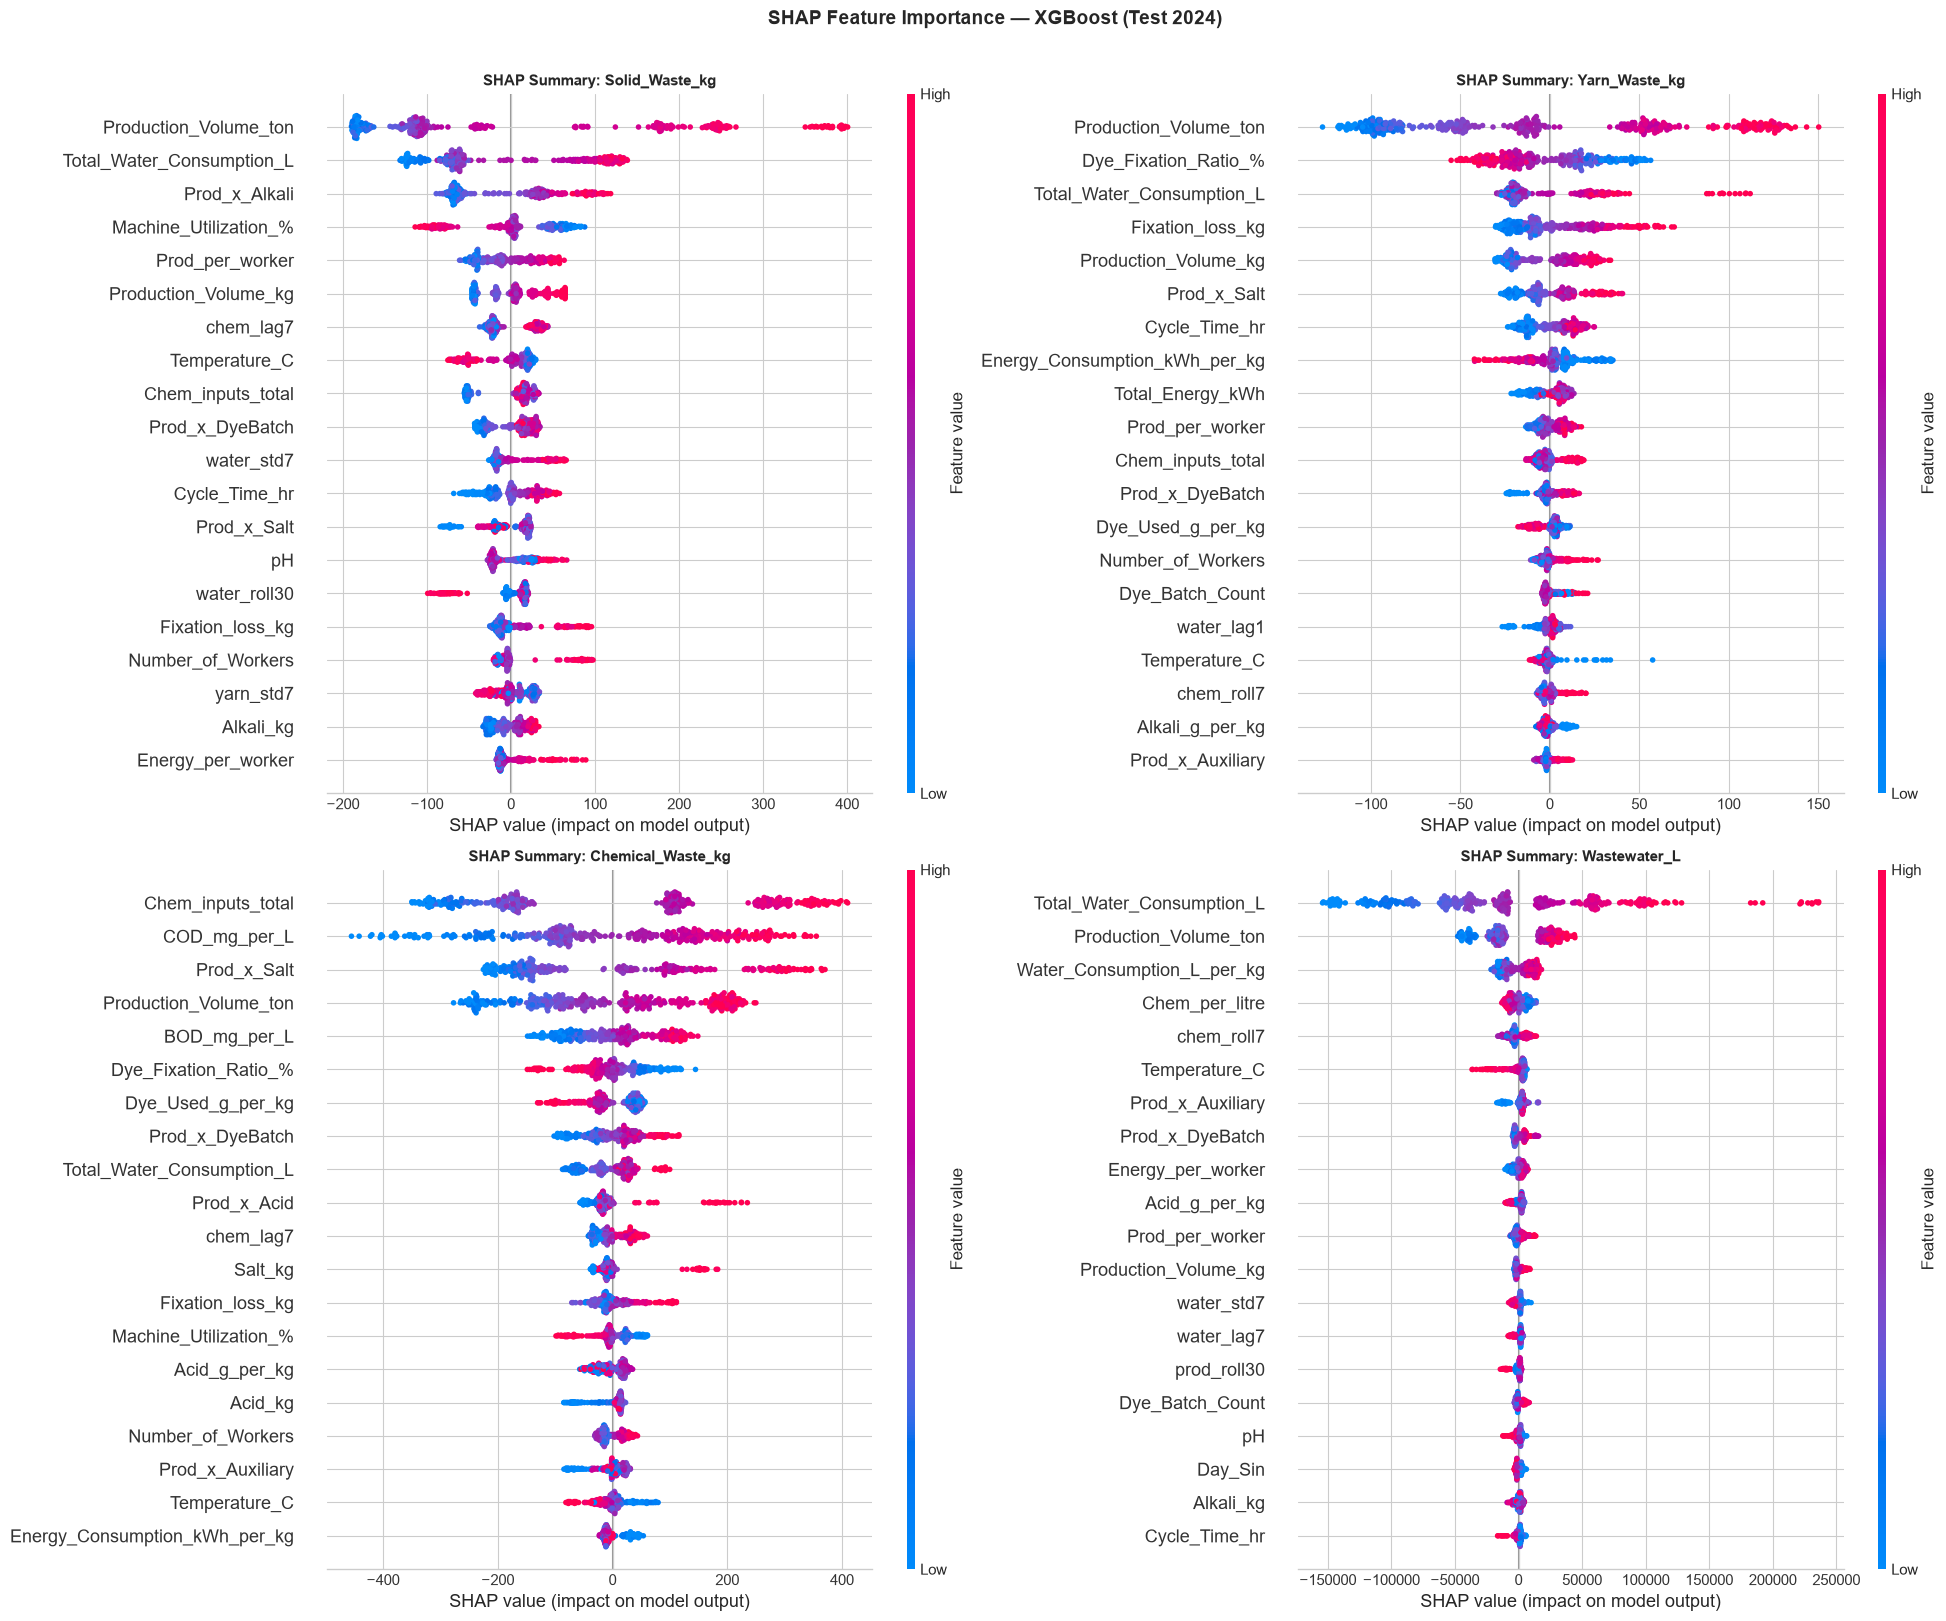

Saved: 14_shap_summary_plots.png


In [24]:
# SHAP Values — Model Explainability
# SHAP (SHapley Additive exPlanations) provides the most principled
# measure of feature contributions for tree-based models.
# We compute SHAP for all 4 targets and plot a beeswarm summary per target.
if SHAP_AVAILABLE:
    print("Computing SHAP values (may take 1-3 minutes)...")
    fig, axes = plt.subplots(2, 2, figsize=(20, 16))

    for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
        estimator = model_final.estimators_[i]
        explainer = shap.TreeExplainer(estimator)
        shap_vals = explainer.shap_values(X_test)

        row, col = divmod(i, 2)
        plt.sca(axes[row, col])
        shap.summary_plot(shap_vals, X_test, feature_names=FEATURE_COLS,
                          show=False, plot_size=None)
        axes[row, col].set_title(f'SHAP Summary: {target}', fontsize=11, fontweight='bold')
        print(f"   SHAP done: {target}")

    plt.suptitle("SHAP Feature Importance — XGBoost (Test 2024)",
                 fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    fig.savefig(f"{OUTPUT_DIR}/14_shap_summary_plots.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved: 14_shap_summary_plots.png")
else:
    print("⚠  SHAP not available — skipping. Install with: pip install shap")

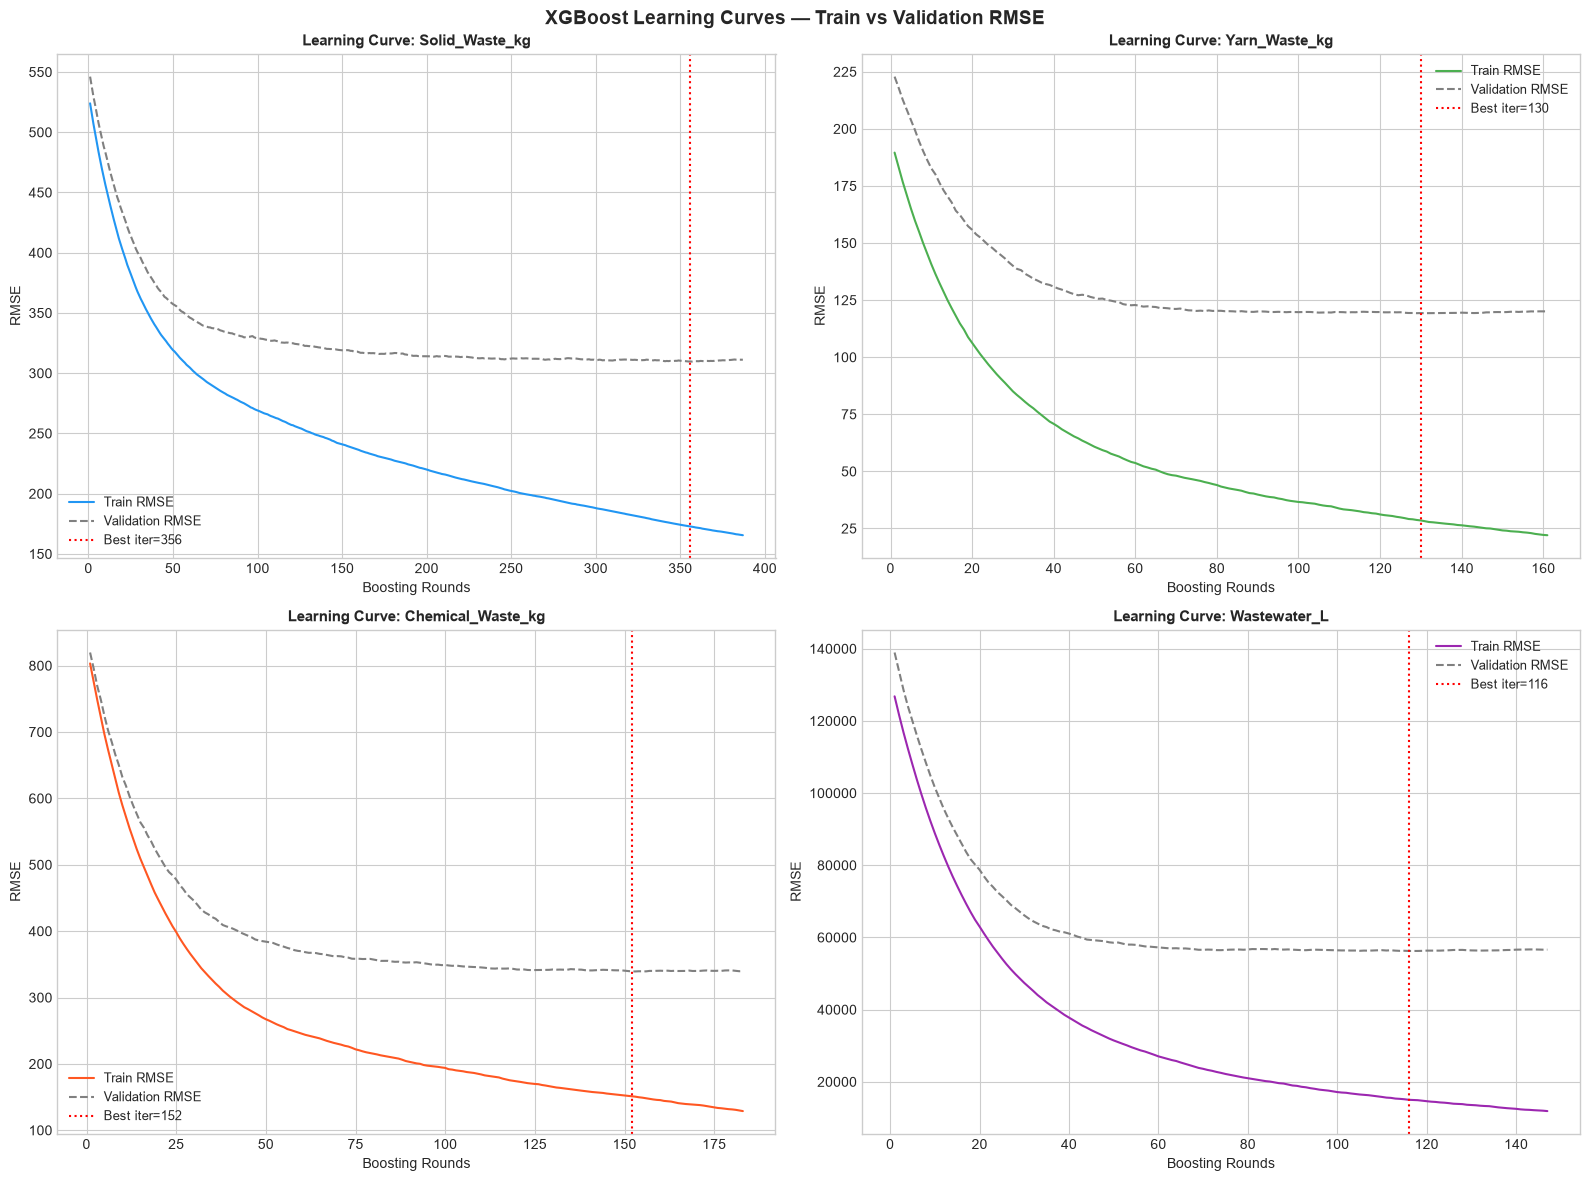

Saved: 15_learning_curves.png


In [25]:
# ============================================================
# CELL 25: Learning Curves — XGBoost Training Dynamics
# ============================================================
# For each target, retrain with an eval set and plot train vs validation RMSE.
# This is unique to XGBoost (not available in Random Forest).
from sklearn.model_selection import train_test_split

X_tr_lc, X_val_lc, idx_tr, idx_val = train_test_split(
    X_train, np.arange(len(X_train)), test_size=0.2, random_state=42
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    y_full = y_train_transformed[target].values
    y_tr   = y_full[idx_tr]
    y_val  = y_full[idx_val]

    lc_params = {k: v for k, v in best_params_per_target[target].items()}
    lc_params['n_estimators'] = 600
    xgb_lc = XGBRegressor(
        **lc_params,
        random_state=42, n_jobs=-1, verbosity=0,
        eval_metric='rmse', early_stopping_rounds=30
    )
    xgb_lc.fit(
        X_tr_lc, y_tr,
        eval_set=[(X_tr_lc, y_tr), (X_val_lc, y_val)],
        verbose=False
    )

    results    = xgb_lc.evals_result()
    train_rmse = results['validation_0']['rmse']
    val_rmse   = results['validation_1']['rmse']
    epochs     = range(1, len(train_rmse) + 1)

    row, col = divmod(i, 2)
    ax = axes[row, col]
    ax.plot(epochs, train_rmse, color=color, linewidth=1.5, label='Train RMSE')
    ax.plot(epochs, val_rmse, color='gray', linestyle='--', linewidth=1.5, label='Validation RMSE')
    best_it = xgb_lc.best_iteration
    ax.axvline(best_it, color='red', linestyle=':', linewidth=1.5, label=f'Best iter={best_it}')
    ax.set_title(f'Learning Curve: {target}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Boosting Rounds')
    ax.set_ylabel('RMSE')
    ax.legend(fontsize=9)

plt.suptitle("XGBoost Learning Curves — Train vs Validation RMSE", fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/15_learning_curves.png", dpi=150)
plt.show()
print("Saved: 15_learning_curves.png")

🏳 Running Walk-Forward CV on all 4 targets with per-target best params...

   Solid_Waste_kg            CV R2: 0.3938 +/- 0.1678
   Yarn_Waste_kg             CV R2: 0.3571 +/- 0.2901
   Chemical_Waste_kg         CV R2: 0.5194 +/- 0.3175
   Wastewater_L              CV R2: 0.5512 +/- 0.2310


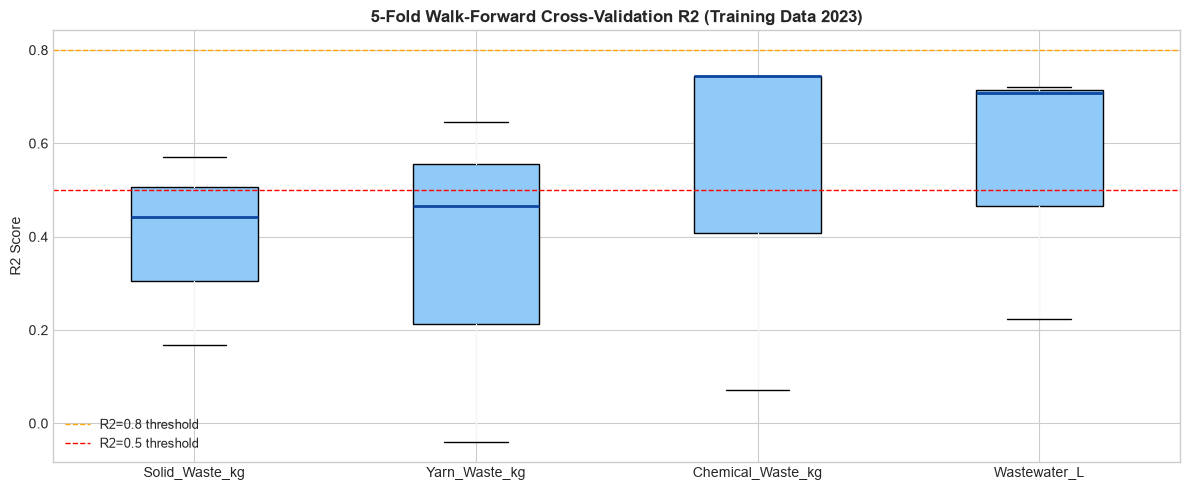

Saved: 16_walk_forward_cv_r2.png


In [26]:
# ============================================================
# CELL 26: Walk-Forward CV - Final Stability Report
# (Report these R^2 values in your paper's methodology section)
# Each target evaluated with ITS OWN best params (Option B).
# ============================================================
print("🏳 Running Walk-Forward CV on all 4 targets with per-target best params...\n")

cv_results = {}
for target in TARGETS:
    scores = []
    y_cv   = y_train_transformed[target].values
    params = best_params_per_target[target]

    for fold, (tr_idx, val_idx) in enumerate(tscv.split(X_train)):
        X_tr  = X_train.iloc[tr_idx]
        X_val = X_train.iloc[val_idx]
        y_tr  = y_cv[tr_idx]
        y_val_orig = y_train[target].values[val_idx]

        est = XGBRegressor(**params, random_state=42, n_jobs=-1, verbosity=0)
        est.fit(X_tr, y_tr)
        y_pred_val = est.predict(X_val)
        if target in LOG_TARGETS:
            y_pred_val = np.expm1(y_pred_val)
        scores.append(r2_score(y_val_orig, y_pred_val))

    cv_results[target] = scores
    print(f"   {target:<25} CV R2: {np.mean(scores):.4f} +/- {np.std(scores):.4f}")

cv_df = pd.DataFrame(cv_results)

fig, ax = plt.subplots(figsize=(12, 5))
cv_df.boxplot(ax=ax, patch_artist=True,
              boxprops=dict(facecolor='#90CAF9'),
              medianprops=dict(color='#0D47A1', linewidth=2))
ax.axhline(0.8, color='orange', linestyle='--', linewidth=1, label='R2=0.8 threshold')
ax.axhline(0.5, color='red', linestyle='--', linewidth=1, label='R2=0.5 threshold')
ax.set_title("5-Fold Walk-Forward Cross-Validation R2 (Training Data 2023)",
             fontsize=12, fontweight='bold')
ax.set_ylabel("R2 Score")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/16_walk_forward_cv_r2.png", dpi=150)
plt.show()
print("Saved: 16_walk_forward_cv_r2.png")

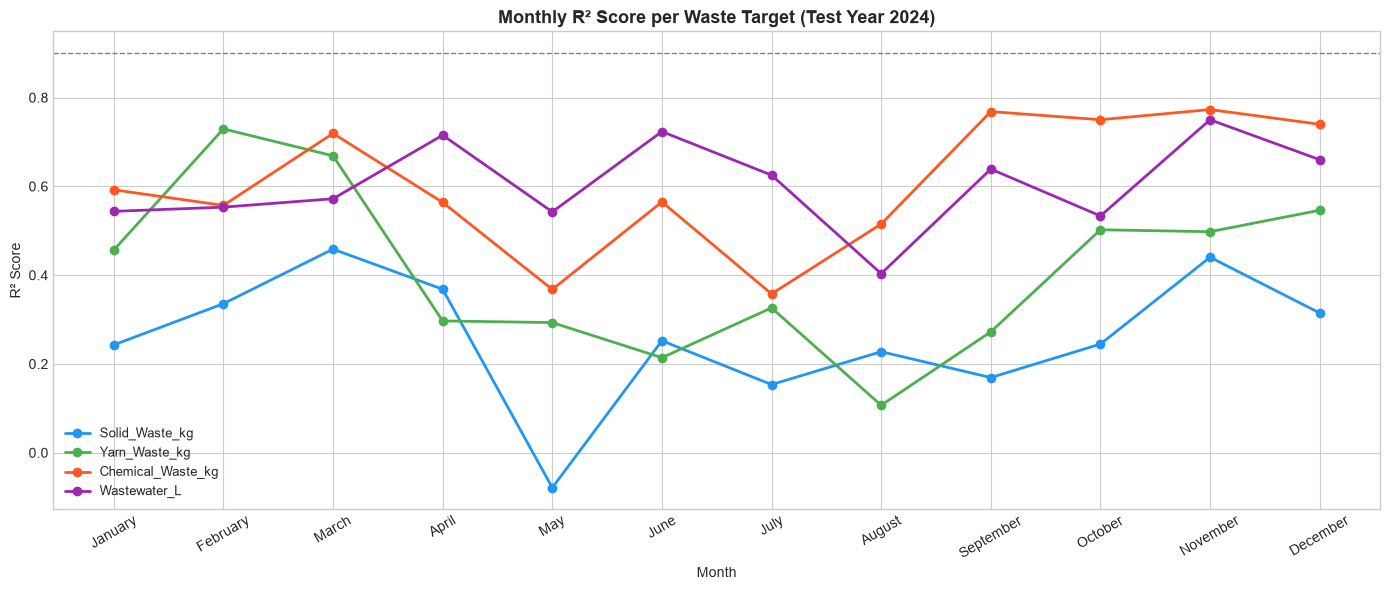

Saved: 17_monthly_r2.png


In [27]:
# ============================================================
# CELL 27: Monthly Performance Analysis (Test Year 2024)
# ============================================================
month_order = ['January','February','March','April','May','June',
               'July','August','September','October','November','December']

df_eval = df_test[['Date', 'Month']].copy().reset_index(drop=True)
df_eval = pd.concat([df_eval,
                     y_test.reset_index(drop=True),
                     y_pred_df.reset_index(drop=True)], axis=1)
df_eval.columns = (list(df_test[['Date','Month']].columns)
                   + [f"{t}_Actual"    for t in TARGETS]
                   + [f"{t}_Predicted" for t in TARGETS])

monthly_r2 = df_eval.groupby('Month').apply(
    lambda g: pd.Series({
        t: r2_score(g[f'{t}_Actual'], g[f'{t}_Predicted']) for t in TARGETS
    })
).reset_index()
monthly_r2['Month_num'] = monthly_r2['Month'].apply(
    lambda x: month_order.index(x) if x in month_order else 12)
monthly_r2 = monthly_r2.sort_values('Month_num')

fig, ax = plt.subplots(figsize=(14, 6))
for target, color in zip(TARGETS, COLORS):
    ax.plot(monthly_r2['Month'], monthly_r2[target],
            marker='o', label=target, color=color, linewidth=2)
ax.axhline(0.9, color='gray', linestyle='--', linewidth=1)
ax.set_title("Monthly R² Score per Waste Target (Test Year 2024)",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Month")
ax.set_ylabel("R² Score")
ax.legend(fontsize=9)
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/17_monthly_r2.png", dpi=150)
plt.show()
print("Saved: 17_monthly_r2.png")

## Random Forest vs XGBoost — Head-to-Head Comparison

The cell below compares this XGBoost model against your Random Forest results on the **same test set, same features, same year-based split**. The `RF_METRICS` dictionary is pre-filled with the final per-target tuned Random Forest numbers from the RF notebook (Cell 15). If you re-run the RF notebook, paste any updated values here.

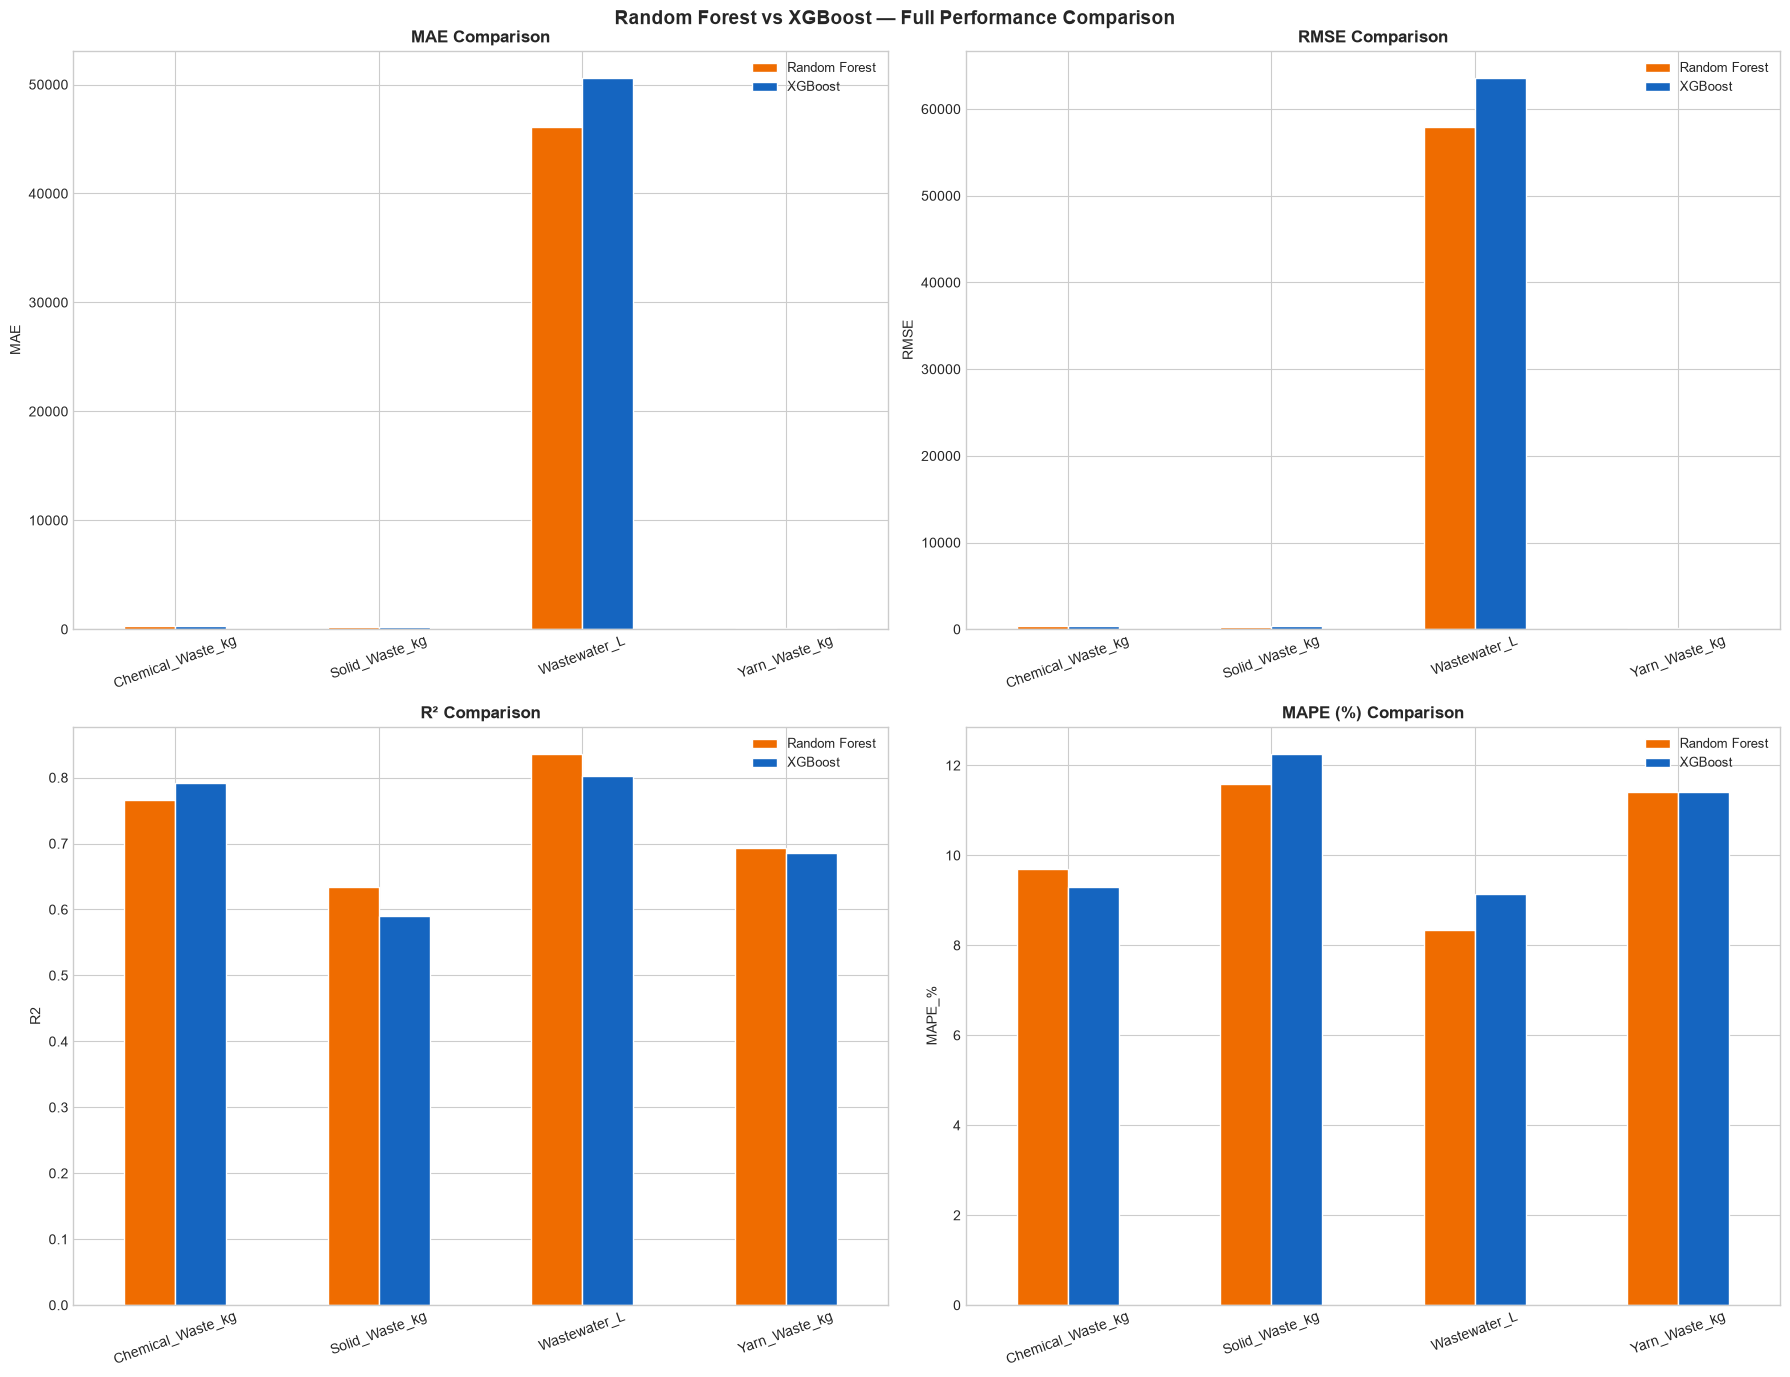

 Saved: 18_rf_vs_xgb_comparison.png
\Full Comparison Table:
           Target         Model       MAE      RMSE     R2  MAPE_%
   Solid_Waste_kg Random Forest   237.447   305.791 0.6339   11.58
   Solid_Waste_kg       XGBoost   252.734   323.462 0.5903   12.25
    Yarn_Waste_kg Random Forest    99.068   121.158 0.6937   11.40
    Yarn_Waste_kg       XGBoost    99.215   122.681 0.6859   11.40
Chemical_Waste_kg Random Forest   324.535   411.373 0.7667    9.69
Chemical_Waste_kg       XGBoost   312.274   389.104 0.7912    9.29
     Wastewater_L Random Forest 46119.431 57983.836 0.8356    8.34
     Wastewater_L       XGBoost 50574.959 63548.702 0.8026    9.15


In [28]:
# ============================================================
# CELL 28: RF vs XGBoost Performance Comparison (Side-by-Side)
# ============================================================
# These are the FINAL per-target tuned Random Forest results
# (from the RF notebook's metrics table). Update if you re-run RF.
RF_METRICS = {
    'Solid_Waste_kg'   : {'MAE': 237.447, 'RMSE': 305.791, 'R2': 0.6339, 'MAPE_%': 11.58},
    'Yarn_Waste_kg'    : {'MAE':  99.068, 'RMSE': 121.158, 'R2': 0.6937, 'MAPE_%': 11.40},
    'Chemical_Waste_kg': {'MAE': 324.535, 'RMSE': 411.373, 'R2': 0.7667, 'MAPE_%':  9.69},
    'Wastewater_L'     : {'MAE':46119.431,'RMSE':57983.836,'R2': 0.8356, 'MAPE_%':  8.34},
}

rows = []
for target in TARGETS:
    xgb_r = metrics_df[metrics_df['Target'] == target].iloc[0]
    rf_r  = RF_METRICS[target]
    rows.append({'Target': target, 'Model': 'Random Forest',
                 'MAE': rf_r['MAE'], 'RMSE': rf_r['RMSE'],
                 'R2': rf_r['R2'], 'MAPE_%': rf_r['MAPE_%']})
    rows.append({'Target': target, 'Model': 'XGBoost',
                 'MAE': xgb_r['MAE'], 'RMSE': xgb_r['RMSE'],
                 'R2': xgb_r['R2'], 'MAPE_%': xgb_r['MAPE_%']})

comp_df = pd.DataFrame(rows)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
metric_keys   = ['MAE', 'RMSE', 'R2', 'MAPE_%']
metric_titles = ['MAE Comparison', 'RMSE Comparison', 'R² Comparison', 'MAPE (%) Comparison']

for ax, key, title in zip(axes.flat, metric_keys, metric_titles):
    pivot = comp_df.pivot(index='Target', columns='Model', values=key)
    pivot.plot(kind='bar', ax=ax, color=['#EF6C00', '#1565C0'], edgecolor='white')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(key)
    ax.tick_params(axis='x', rotation=20)
    ax.legend(fontsize=9)

plt.suptitle("Random Forest vs XGBoost — Full Performance Comparison",
             fontsize=14, fontweight='bold')
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/18_rf_vs_xgb_comparison.png", dpi=150)
plt.show()
print(" Saved: 18_rf_vs_xgb_comparison.png")

print("\Full Comparison Table:")
print(comp_df.to_string(index=False))

In [29]:
# ============================================================
# CELL 29: Save Final Model & Predictions
# ============================================================
import json as _json

model_path = f"{OUTPUT_DIR}/xgboost_waste_model_improved.pkl"
joblib.dump(model_final, model_path)
print(f"Model saved: {model_path}")

# Save per-target best hyperparameters (portable, reload-safe)
params_path = f"{OUTPUT_DIR}/best_params_per_target_xgb.json"
with open(params_path, 'w') as f:
    _json.dump({t: best_params_per_target[t] for t in TARGETS}, f, indent=2)
print(f"Per-target best params saved: {params_path}")

# Save predictions with actuals and residuals
results_df = df_test[['Date', 'Month']].reset_index(drop=True).copy()
for target in TARGETS:
    results_df[f'{target}_Actual']    = y_test[target].values
    results_df[f'{target}_Predicted'] = y_pred_df[target].values
    results_df[f'{target}_Error']     = y_test[target].values - y_pred_df[target].values

results_path = f"{OUTPUT_DIR}/predictions_2024_xgb_improved.csv"
results_df.to_csv(results_path, index=False)
print(f"Predictions saved: {results_path}")

Model saved: output_figures_xgb/xgboost_waste_model_improved.pkl
Per-target best params saved: output_figures_xgb/best_params_per_target_xgb.json
Predictions saved: output_figures_xgb/predictions_2024_xgb_improved.csv


In [30]:
# ============================================================
# CELL 30: Automated Future Prediction Template
# ============================================================
def predict_new_data(date_string, factory_values):
    """
    date_string  : 'YYYY-MM-DD'
    factory_values: dict of raw process variables
    """
    input_df = pd.DataFrame([factory_values])
    input_df['Date'] = pd.to_datetime(date_string)

    m  = input_df['Date'].dt.month.values[0]
    dw = input_df['Date'].dt.dayofweek.values[0]
    input_df['Month_Sin'] = np.sin(2 * np.pi * m / 12)
    input_df['Month_Cos'] = np.cos(2 * np.pi * m / 12)
    input_df['Day_Sin']   = np.sin(2 * np.pi * dw / 7)
    input_df['Day_Cos']   = np.cos(2 * np.pi * dw / 7)
    input_df['Quarter']   = input_df['Date'].dt.quarter

    input_df['Prod_x_DyeBatch'] = input_df['Production_Volume_kg'] * input_df['Dye_Batch_Count']
    input_df['Prod_x_Acid']     = input_df['Production_Volume_kg'] * input_df['Acid_kg']
    input_df['Prod_x_Salt']     = input_df['Production_Volume_kg'] * input_df['Salt_kg']
    input_df['Prod_x_Alkali']   = input_df['Production_Volume_kg'] * input_df['Alkali_kg']
    input_df['Prod_x_Auxiliary']= input_df['Production_Volume_kg'] * input_df['Auxiliary_kg']
    input_df['Chem_inputs_total'] = (input_df['Acid_kg'] + input_df['Salt_kg']
                                     + input_df['Alkali_kg'] + input_df['Auxiliary_kg']
                                     + input_df['Dye_Used_kg'])
    input_df['Fixation_loss_kg'] = (1 - input_df['Dye_Fixation_Ratio_%']/100) * input_df['Dye_Used_kg']
    input_df['Chem_per_litre']   = input_df['Chem_inputs_total'] / (input_df['Total_Water_Consumption_L'] + 1)
    input_df['Energy_per_worker']= input_df['Total_Energy_kWh'] / (input_df['Number_of_Workers'] + 1)
    input_df['Prod_per_worker']  = input_df['Production_Volume_kg'] / (input_df['Number_of_Workers'] + 1)

    # Use last-30-day means as proxy for lag/rolling features
    for col, prefix in LAG_COLS:
        last_mean = df[col].tail(30).mean()
        last_std  = df[col].tail(30).std()
        input_df[f'{prefix}_lag1']   = last_mean
        input_df[f'{prefix}_lag7']   = last_mean
        input_df[f'{prefix}_roll7']  = last_mean
        input_df[f'{prefix}_roll30'] = last_mean
        input_df[f'{prefix}_std7']   = last_std

    preds = model_final.predict(input_df[FEATURE_COLS])[0]

    print(f"\n🏭 WASTE PREDICTION FOR: {date_string}")
    print("-" * 40)
    for target, val in zip(TARGETS, preds):
        actual_val = np.expm1(val) if target in LOG_TARGETS else val
        print(f"   📦 {target:<25}: {actual_val:.2f}")


# — Example usage —
user_inputs = {
    'Production_Volume_kg': 15000, 'Machine_Utilization_%': 85,
    'Number_of_Workers': 100,      'Total_Energy_kWh': 25000,
    'Total_Water_Consumption_L': 750000, 'Dye_Fixation_Ratio_%': 65,
    'Liquor_Ratio_1x': 8.5,        'Temperature_C': 65,
    'Cycle_Time_hr': 6,            'Dye_Batch_Count': 280,
    'Dye_Used_kg': 50,             'Salt_kg': 320,
    'Alkali_kg': 110,              'Acid_kg': 30,
    'Auxiliary_kg': 80,            'BOD_mg_per_L': 200,
    'COD_mg_per_L': 850,           'pH': 8.5,
    'Energy_Consumption_kWh_per_kg': 1.67,
    'Water_Consumption_L_per_kg': 50,
    'Production_Volume_ton': 15,
    'Monthly_Demand_Factor': 1.0,
    'Dye_Used_g_per_kg': 27, 'Salt_g_per_kg': 280,
    'Alkali_g_per_kg': 73,   'Acid_g_per_kg': 50,
    'Auxiliary_g_per_kg': 70,
}
predict_new_data('2025-07-15', user_inputs)


🏭 WASTE PREDICTION FOR: 2025-07-15
----------------------------------------
   📦 Solid_Waste_kg           : 1884.46
   📦 Yarn_Waste_kg            : 937.68
   📦 Chemical_Waste_kg        : 3062.52
   📦 Wastewater_L             : 611924.00


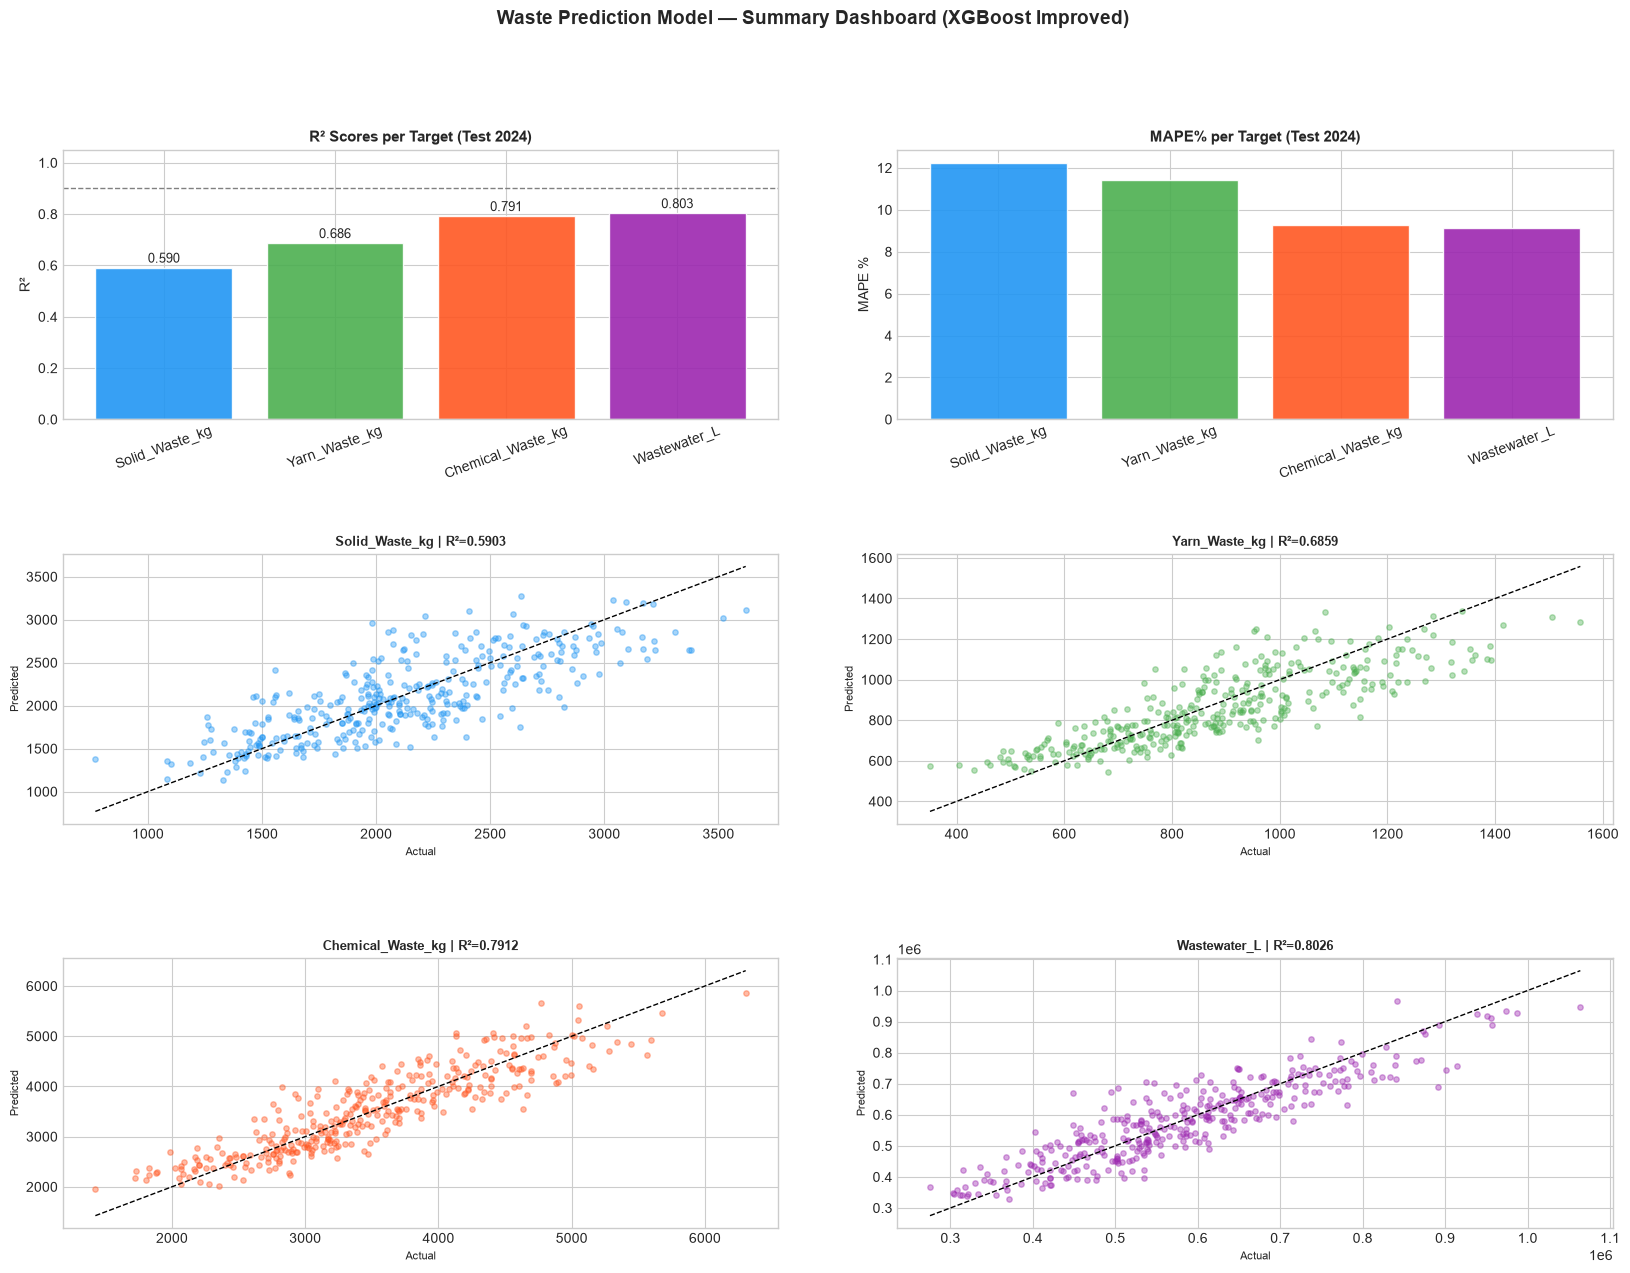

📁 Saved: 19_summary_dashboard.png


In [31]:
# ============================================================
# CELL 31: Summary Dashboard Figure
# ============================================================
fig = plt.figure(figsize=(20, 14))
gs  = gridspec.GridSpec(3, 4, figure=fig, hspace=0.5, wspace=0.4)

ax_r2 = fig.add_subplot(gs[0, :2])
r2_scores = [r2_score(y_test[t], y_pred_df[t]) for t in TARGETS]
bars = ax_r2.bar(TARGETS, r2_scores, color=COLORS, edgecolor='white', alpha=0.9)
ax_r2.axhline(0.9, color='gray', linestyle='--', linewidth=1)
ax_r2.set_ylim(0, 1.05)
ax_r2.set_title("R² Scores per Target (Test 2024)", fontsize=11, fontweight='bold')
ax_r2.set_ylabel("R²")
ax_r2.tick_params(axis='x', rotation=20)
for bar, score in zip(bars, r2_scores):
    ax_r2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
               f'{score:.3f}', ha='center', va='bottom', fontsize=9)

ax_mape = fig.add_subplot(gs[0, 2:])
mape_scores = [mean_absolute_percentage_error(y_test[t], y_pred_df[t]) * 100 for t in TARGETS]
ax_mape.bar(TARGETS, mape_scores, color=COLORS, edgecolor='white', alpha=0.9)
ax_mape.set_title("MAPE% per Target (Test 2024)", fontsize=11, fontweight='bold')
ax_mape.set_ylabel("MAPE %")
ax_mape.tick_params(axis='x', rotation=20)

for i, (target, color) in enumerate(zip(TARGETS, COLORS)):
    row = 1 + i // 2
    col = (i % 2) * 2
    ax  = fig.add_subplot(gs[row, col:col+2])
    y_true_col = y_test[target].values
    y_pred_col = y_pred_df[target].values
    ax.scatter(y_true_col, y_pred_col, alpha=0.4, color=color, s=15)
    mn = min(y_true_col.min(), y_pred_col.min())
    mx = max(y_true_col.max(), y_pred_col.max())
    ax.plot([mn, mx], [mn, mx], 'k--', linewidth=1)
    r2 = r2_score(y_true_col, y_pred_col)
    ax.set_title(f'{target} | R²={r2:.4f}', fontsize=9, fontweight='bold')
    ax.set_xlabel('Actual', fontsize=8)
    ax.set_ylabel('Predicted', fontsize=8)

plt.suptitle("Waste Prediction Model — Summary Dashboard (XGBoost Improved)",
             fontsize=14, fontweight='bold')
fig.savefig(f"{OUTPUT_DIR}/19_summary_dashboard.png", dpi=150, bbox_inches='tight')
plt.show()
print("📁 Saved: 19_summary_dashboard.png")

## 🆕 Reverse Logistics — Treated Wastewater Recovery

This mirrors the final cell of the Random Forest notebook. Using the predicted waste streams, we estimate the volume of **treated wastewater** that can be recovered and recycled back into the dyeing process — the core of the circular-supply-chain objective.

The treated volume is modelled as the predicted wastewater minus the share lost to chemical sludge during treatment (proportional to predicted chemical waste). The result is clipped at zero so it is never negative.

✅ New file saved: output_figures_xgb/predictions_2024_RL_improved.csv
   New column   : Treated_Wastewater_L
   Total columns: 15

♻  Reverse Logistics Summary (2024):
   Total predicted wastewater : 208,029,536 L
   Total recoverable (treated): 207,021,824 L
   Recovery rate              : 99.5%


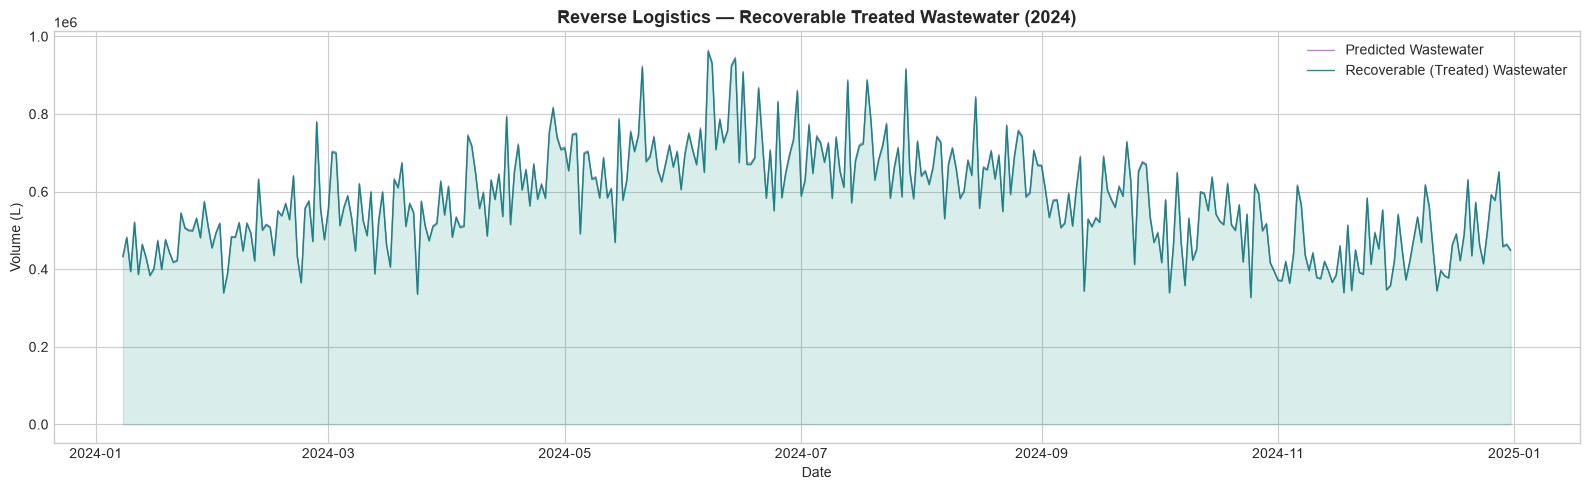

📁 Saved: 20_reverse_logistics_treated_water.png


In [32]:
# ============================================================
# CELL 32: Reverse Logistics — Treated Wastewater CSV
# ============================================================
rl_df = results_df.copy()
rl_df['Treated_Wastewater_L'] = (
    rl_df['Wastewater_L_Predicted'] -
    (rl_df['Chemical_Waste_kg_Predicted'] * 0.8)
).clip(lower=0)

rl_path = f"{OUTPUT_DIR}/predictions_2024_RL_improved.csv"
rl_df.to_csv(rl_path, index=False)
print(f"✅ New file saved: {rl_path}")
print(f"   New column   : Treated_Wastewater_L")
print(f"   Total columns: {len(rl_df.columns)}")

# Recovery summary
total_predicted = rl_df['Wastewater_L_Predicted'].sum()
total_treated   = rl_df['Treated_Wastewater_L'].sum()
recovery_pct    = (total_treated / total_predicted) * 100 if total_predicted else 0
print(f"\n♻  Reverse Logistics Summary (2024):")
print(f"   Total predicted wastewater : {total_predicted:,.0f} L")
print(f"   Total recoverable (treated): {total_treated:,.0f} L")
print(f"   Recovery rate              : {recovery_pct:.1f}%")

# Quick visual of recoverable volume over the test year
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(rl_df['Date'], rl_df['Wastewater_L_Predicted'], color='#9C27B0',
        linewidth=1, alpha=0.6, label='Predicted Wastewater')
ax.plot(rl_df['Date'], rl_df['Treated_Wastewater_L'], color='#00897B',
        linewidth=1, alpha=0.9, label='Recoverable (Treated) Wastewater')
ax.fill_between(rl_df['Date'], rl_df['Treated_Wastewater_L'], color='#00897B', alpha=0.15)
ax.set_title("Reverse Logistics — Recoverable Treated Wastewater (2024)",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Date")
ax.set_ylabel("Volume (L)")
ax.legend(fontsize=10)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/20_reverse_logistics_treated_water.png", dpi=150)
plt.show()
print("📁 Saved: 20_reverse_logistics_treated_water.png")

In [33]:
# ============================================================
# CELL 33: Final Summary Report
# ============================================================
print("=" * 70)
print(" XGBoost WASTE PREDICTION MODEL — FINAL SUMMARY")
print("=" * 70)
print(f" Dataset      : Textile_Dyeing_Dataset_Causal.xlsx")
print(f" Train Period : Year 2023 ({len(X_train)} records)")
print(f" Test Period  : Year 2024 ({len(X_test)} records)")
print(f" Features     : {len(FEATURE_COLS)} (incl. cyclical/lag/rolling/interaction)")
print(f" Targets      : {TARGETS}")
print("")
print(" Test Set Performance (Tuned XGBoost):")
print(f"{'Target':<25} {'R²':>8} {'MAE':>12} {'RMSE':>12} {'MAPE%':>8}")
print("-" * 70)
for _, row in metrics_df.iterrows():
    print(f"{row['Target']:<25} {row['R2']:>8.4f} {row['MAE']:>12.3f} "
          f"{row['RMSE']:>12.3f} {row['MAPE_%']:>7.2f}%")
print("=" * 70)
print("\n SUMMARY OF IMPROVEMENTS:")
print("  1. Lag & Rolling Features  -> 25 new time-series features")
print("  2. Interaction Features    -> Prod×DyeBatch, Fixation_loss_kg, etc.")
print("  3. Skew Check              -> all targets within ±0.5, NO log transform")
print("  4. Walk-Forward CV         -> TimeSeriesSplit(n_splits=5, gap=7) + PER-TARGET tuning")
print("  5. XGBoost explainability  -> gain/weight/cover importance, SHAP, learning curves")
print("  6. Reverse Logistics       -> treated-wastewater recovery output")
print(f"\n📁 All output files saved to: '{OUTPUT_DIR}/'")
print("   Figures are ready to insert directly into your thesis.")
print("\n🚀 ALL CELLS COMPLETED SUCCESSFULLY!")

 XGBoost WASTE PREDICTION MODEL — FINAL SUMMARY
 Dataset      : Textile_Dyeing_Dataset_Causal.xlsx
 Train Period : Year 2023 (358 records)
 Test Period  : Year 2024 (359 records)
 Features     : 67 (incl. cyclical/lag/rolling/interaction)
 Targets      : ['Solid_Waste_kg', 'Yarn_Waste_kg', 'Chemical_Waste_kg', 'Wastewater_L']

 Test Set Performance (Tuned XGBoost):
Target                          R²          MAE         RMSE    MAPE%
----------------------------------------------------------------------
Solid_Waste_kg              0.5903      252.734      323.462   12.25%
Yarn_Waste_kg               0.6859       99.215      122.681   11.40%
Chemical_Waste_kg           0.7912      312.274      389.104    9.29%
Wastewater_L                0.8026    50574.959    63548.702    9.15%

 SUMMARY OF IMPROVEMENTS:
  1. Lag & Rolling Features  -> 25 new time-series features
  2. Interaction Features    -> Prod×DyeBatch, Fixation_loss_kg, etc.
  3. Skew Check              -> all targets within ±0.